# Figure 1 — multi-omic QTL discovery across ancestries in *All of Us*


This notebook reproduces **Figure 1** and its supplemental. The figure summarizes
cis-QTL discovery across three molecular assays — expression (eQTL), protein
(pQTL) and splicing (sQTL) — in the ancestrally diverse *All of Us* cohort:
cohort composition, the proportion of genes with significant QTLs by sample size,
novelty relative to prior consortia, and the SuSiE fine-mapping architecture of
causal variants.

It runs the modular pipeline in `Fig1/` step by step: a shared **setup**, then
one cell per **panel** (each loads only the inputs it needs and caches its ggplot
object), then **assembly** into the final figure.


## How to run

* **Kernel:** R (IRkernel). **Working directory:** the repository root (the folder that contains `Fig1/`).
* Run the cells top to bottom. Each panel caches its ggplot object to `Fig1/objects/`, and the assembly cell reads those back.
* Re-running a single panel cell rebuilds just that panel; re-run the assembly cell to recompose.


### Inputs

> **Controlled-access.** Every input derives from *All of Us* controlled-access
> data and is not in this repository. This notebook is meant to run on the
> Researcher Workbench, where the data lives.

Inputs are **manifest-driven** (`Fig1/inputs.tsv`). Each panel names the logical
inputs it needs by *key*; the loaders (`input_path`, `load_input`, `input_files`)
resolve a key to file(s) and stage them from Google Cloud with `gsutil` **only if
the local copy is missing**. Pre-staged files are used as-is.


## Setup

`00_setup.R` is the shared foundation every step builds on: it loads the libraries, sets the **Inter** font with a matched output **DPI**, defines the `theme_set`/`SZ_*` design system and the env-overridable paths, and brings in the manifest loaders and the folded-in analysis / plot functions — so the figure is self-contained.


In [1]:
## Locate the figure directory. Terra / Linux is case-sensitive, so match
## either "Fig1" or "fig1" and point the pipeline's env-overridable
## paths at it before sourcing the shared setup.
fig_dir <- list.files(".", pattern = "^(Fig1|fig1)$", include.dirs = TRUE)
stopifnot("Run this notebook from the repository root (the folder holding Fig1/)." =
          length(fig_dir) == 1)
Sys.setenv(FIG1_MANIFEST = file.path(fig_dir, "inputs.tsv"),
           FIG1_OBJ = file.path(fig_dir, "objects"))
source(file.path(fig_dir, "00_setup.R"))

## Inline rendering. The canvas resolution is matched to DPI because 00_setup.R
## pins showtext to it (showtext_opts(dpi = DPI)); if the two disagree, every
## label renders at the wrong size. Panels display at a readable default, and
## the assemble cell overrides these with the composed figure's true aspect.
options(repr.plot.width = 7.5, repr.plot.height = 5, repr.plot.res = DPI)
cat("Setup loaded from", fig_dir, "\n")


Warning message:
“package ‘ggplot2’ was built under R version 4.3.3”


Warning message:
“package ‘scales’ was built under R version 4.3.3”


Warning message:
“package ‘patchwork’ was built under R version 4.3.3”


Warning message:
“package ‘showtext’ was built under R version 4.3.3”


Warning message:
“package ‘sysfonts’ was built under R version 4.3.3”


Warning message:
“package ‘showtextdb’ was built under R version 4.3.3”


Setup loaded from Fig1 


### Panels

Each panel below **loads only the inputs it needs** (staging them on demand), does its wrangling, builds one ggplot object, caches it to `Fig1/objects/`, and renders it inline.


### Panel A — study-design schematic placeholder (diagram added externally)

Panel A is a reserved slot for the hand-drawn study-design schematic. The code emits a blank placeholder so the assembled layout keeps A's position; the diagram is dropped in externally.


Panel A built.



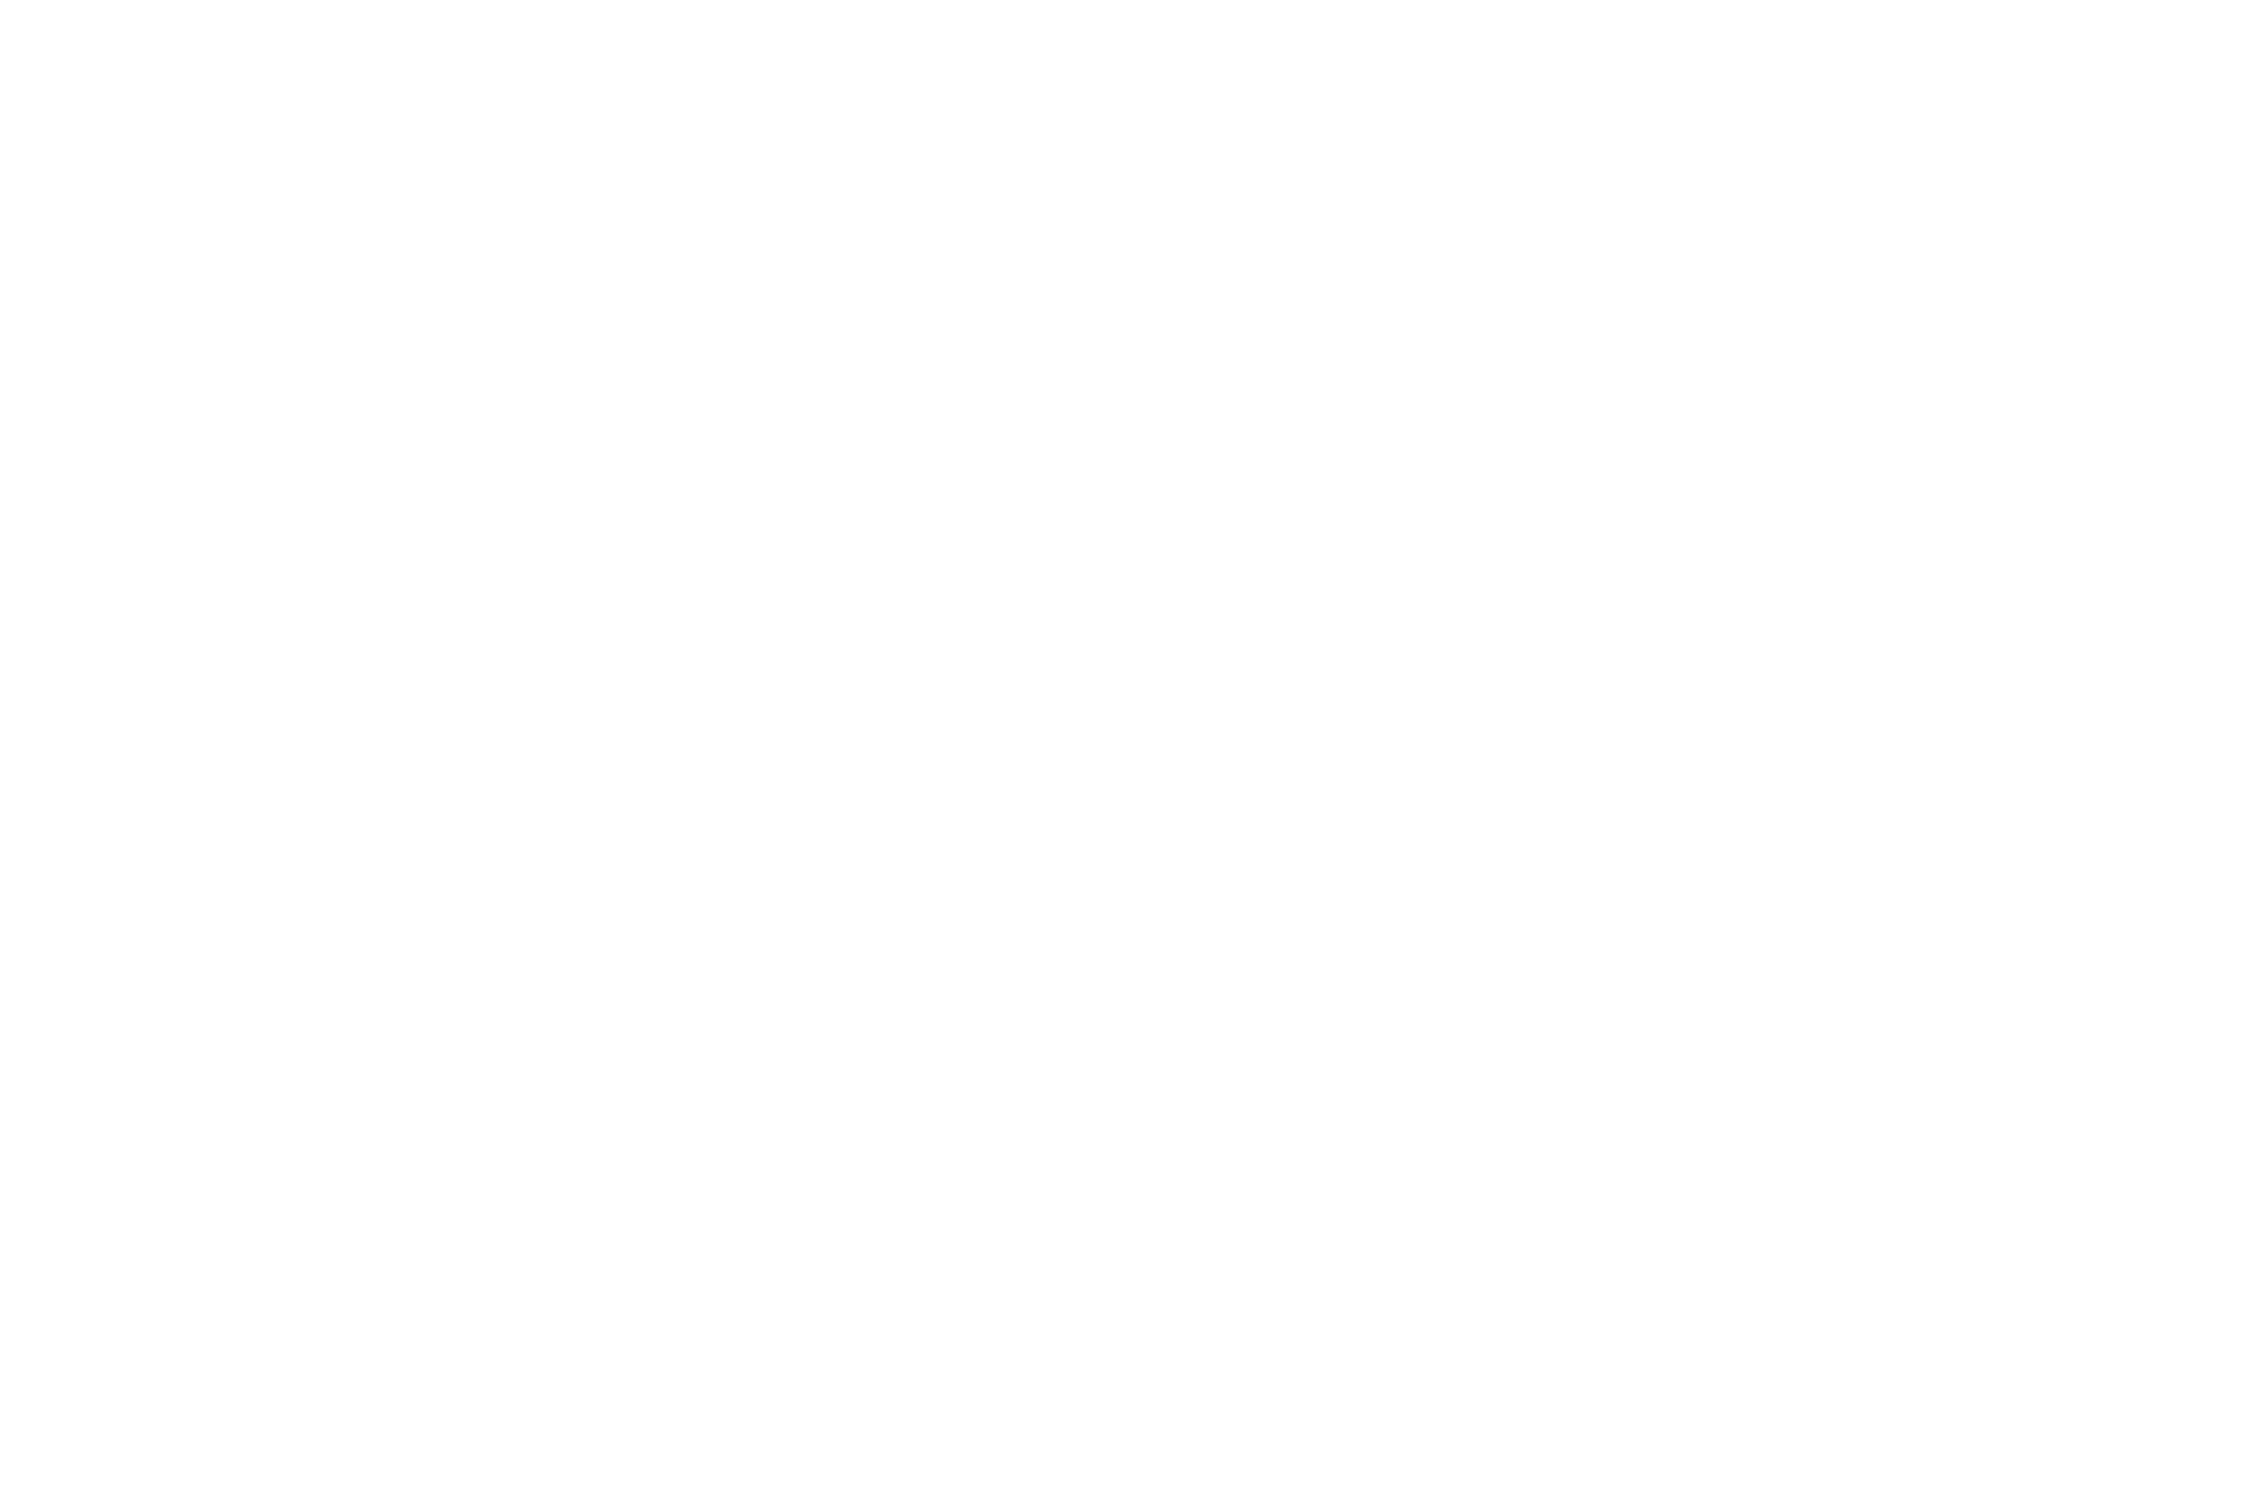

In [2]:
pA <- blank_plot

saveRDS(pA, file.path(OBJ_DIR, "A.rds"))
message("Panel A built.")

pA


### Panel B — ancestry counts in cohort

Counts participants per genetic-ancestry group by joining the ancestry predictions to the combined QTL sample list, then plots the per-group totals — the cohort composition the rest of the figure conditions on.

*Inputs: comb_sample_list, ancestry_preds*


Panel B built.



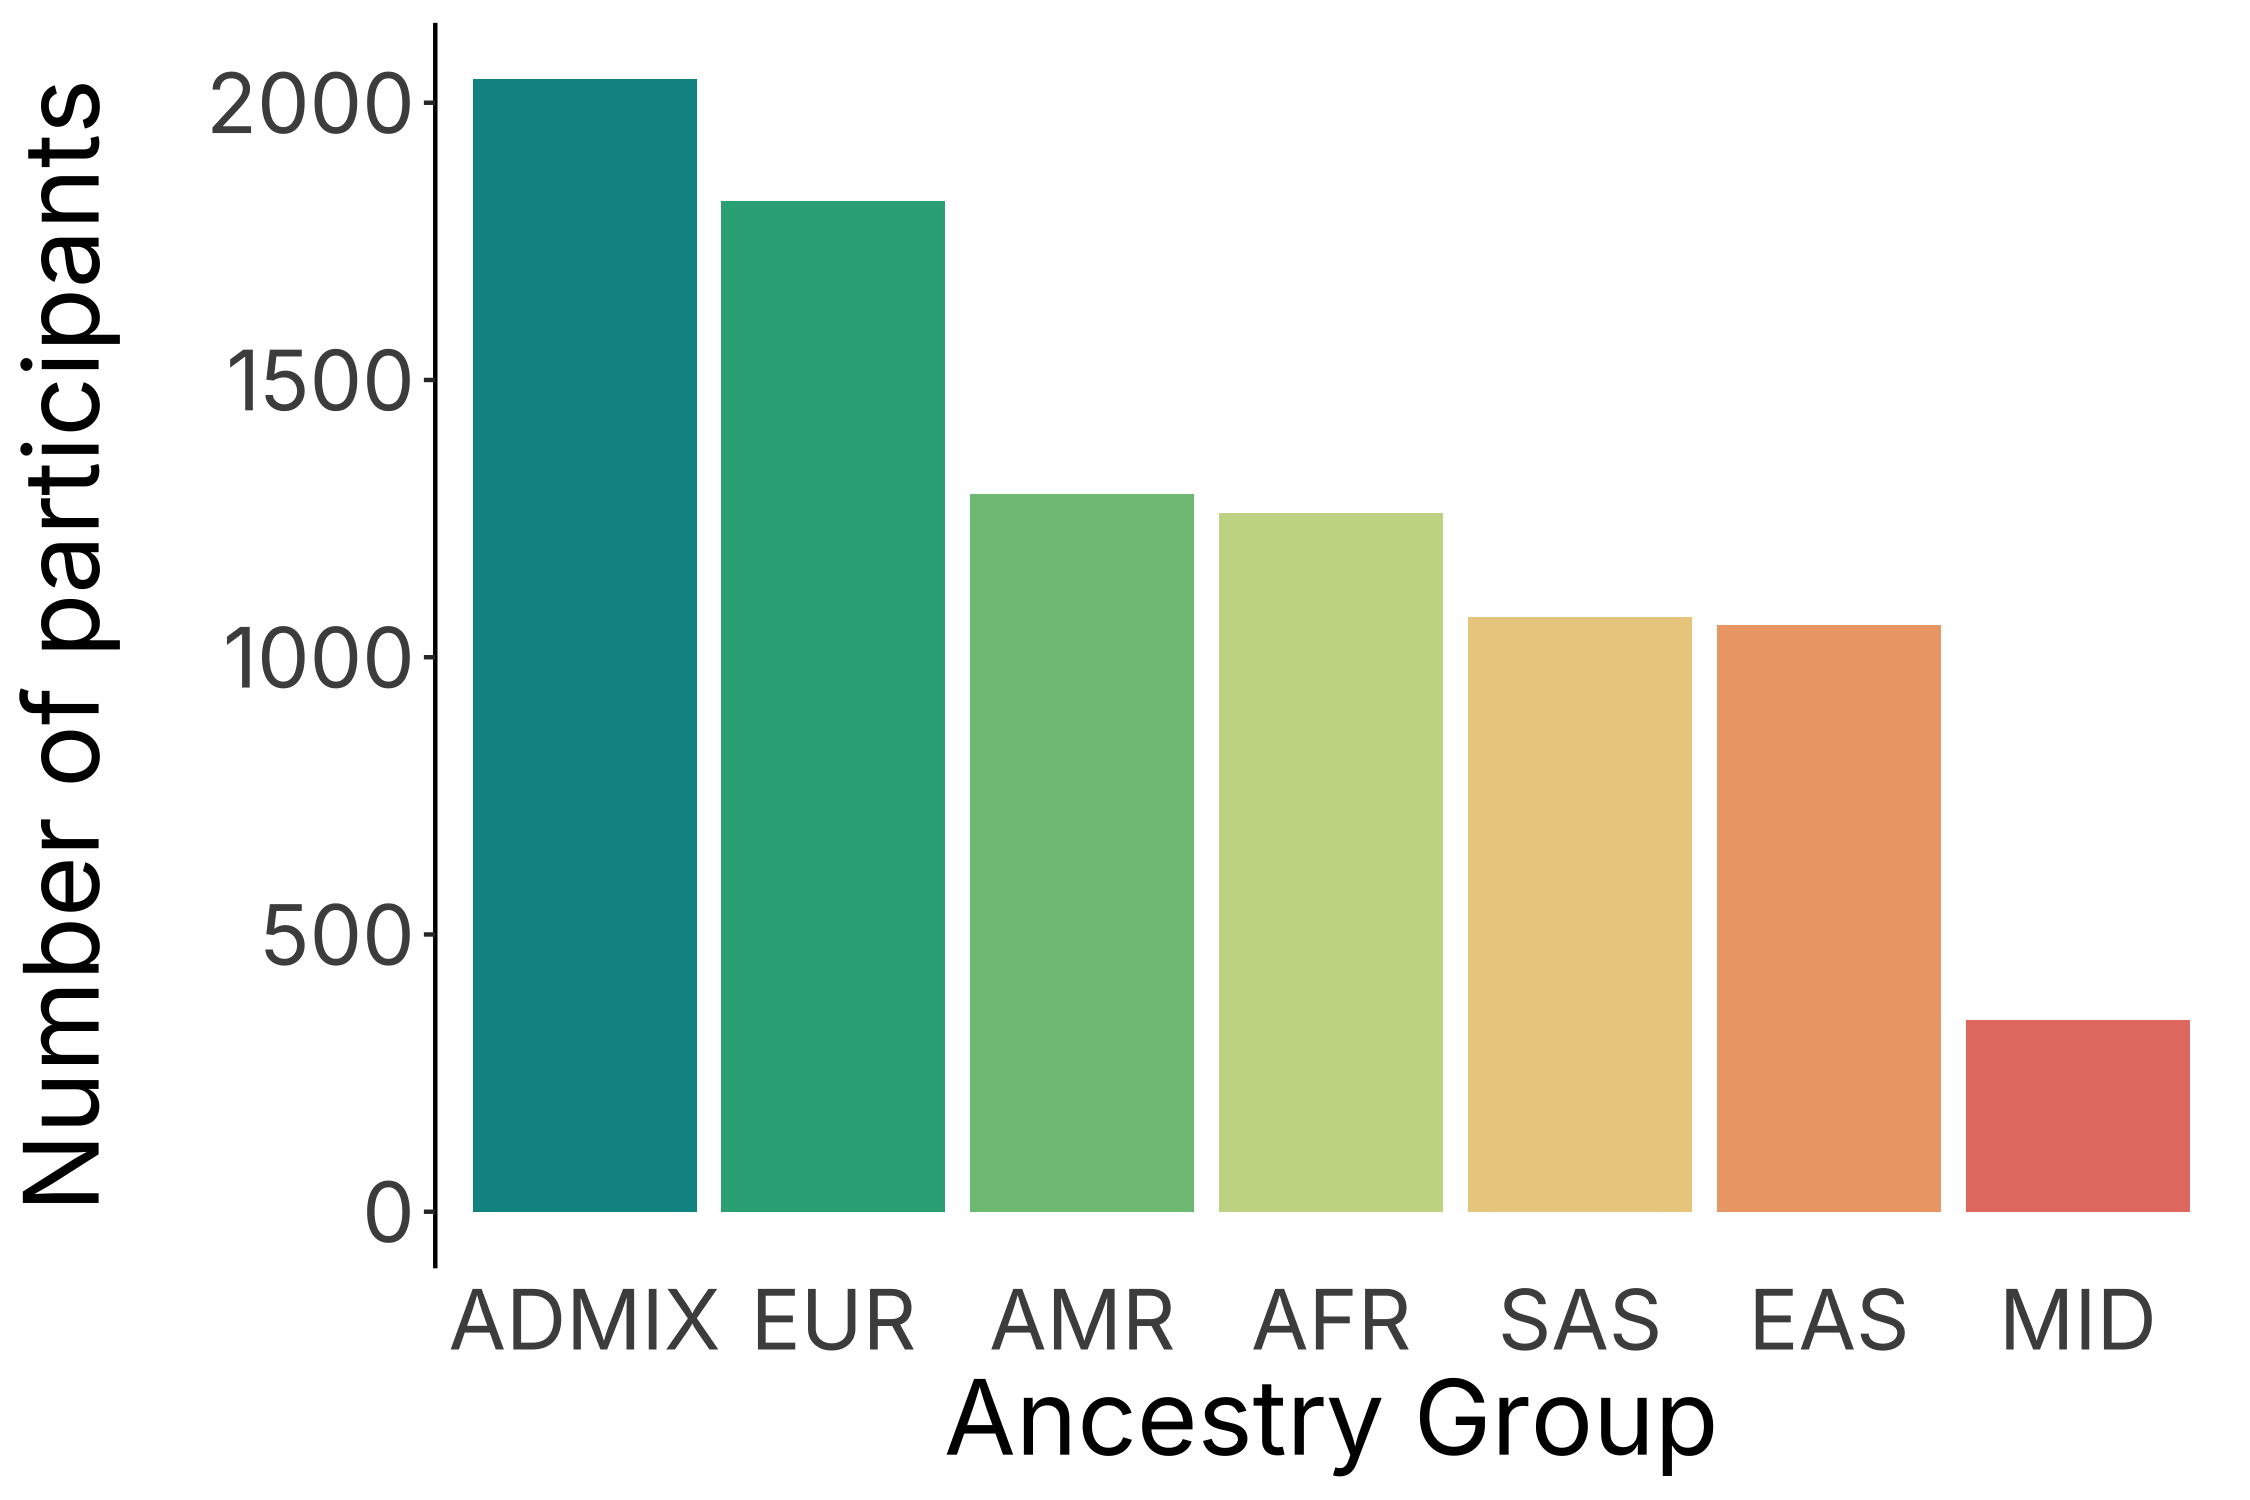

In [3]:
sample_ids <- fread(input_path("comb_sample_list"))$research_id
ancestry_counts <- LoadAncestryCounts(input_path("ancestry_preds"), sample_ids)

pB <- PlotAncestryCounts(ancestry_counts)

saveRDS(pB, file.path(OBJ_DIR, "B.rds"))
message("Panel B built.")

pB


### Panel C — proportion of genes with significant QTLs (expression | splicing + protein)

For every ancestry × assay, computes the proportion of tested genes with at least one significant QTL — FDR-controlled **within** each permutation file — and plots it against the group's sample size, so discovery is shown scaling with N. Expression sits beside splicing + protein.

*Inputs: perm (all assays), ancestry_preds, comb_sample_list*


`summarise()` has grouped output by 'group'. You can override using the
`.groups` argument.


Warning message:
“A numeric `legend.position` argument in `theme()` was deprecated in ggplot2
3.5.0.
ℹ Please use the `legend.position.inside` argument of `theme()` instead.”


Panel C built.



Warning message:
“Duplicated `override.aes` is ignored.”


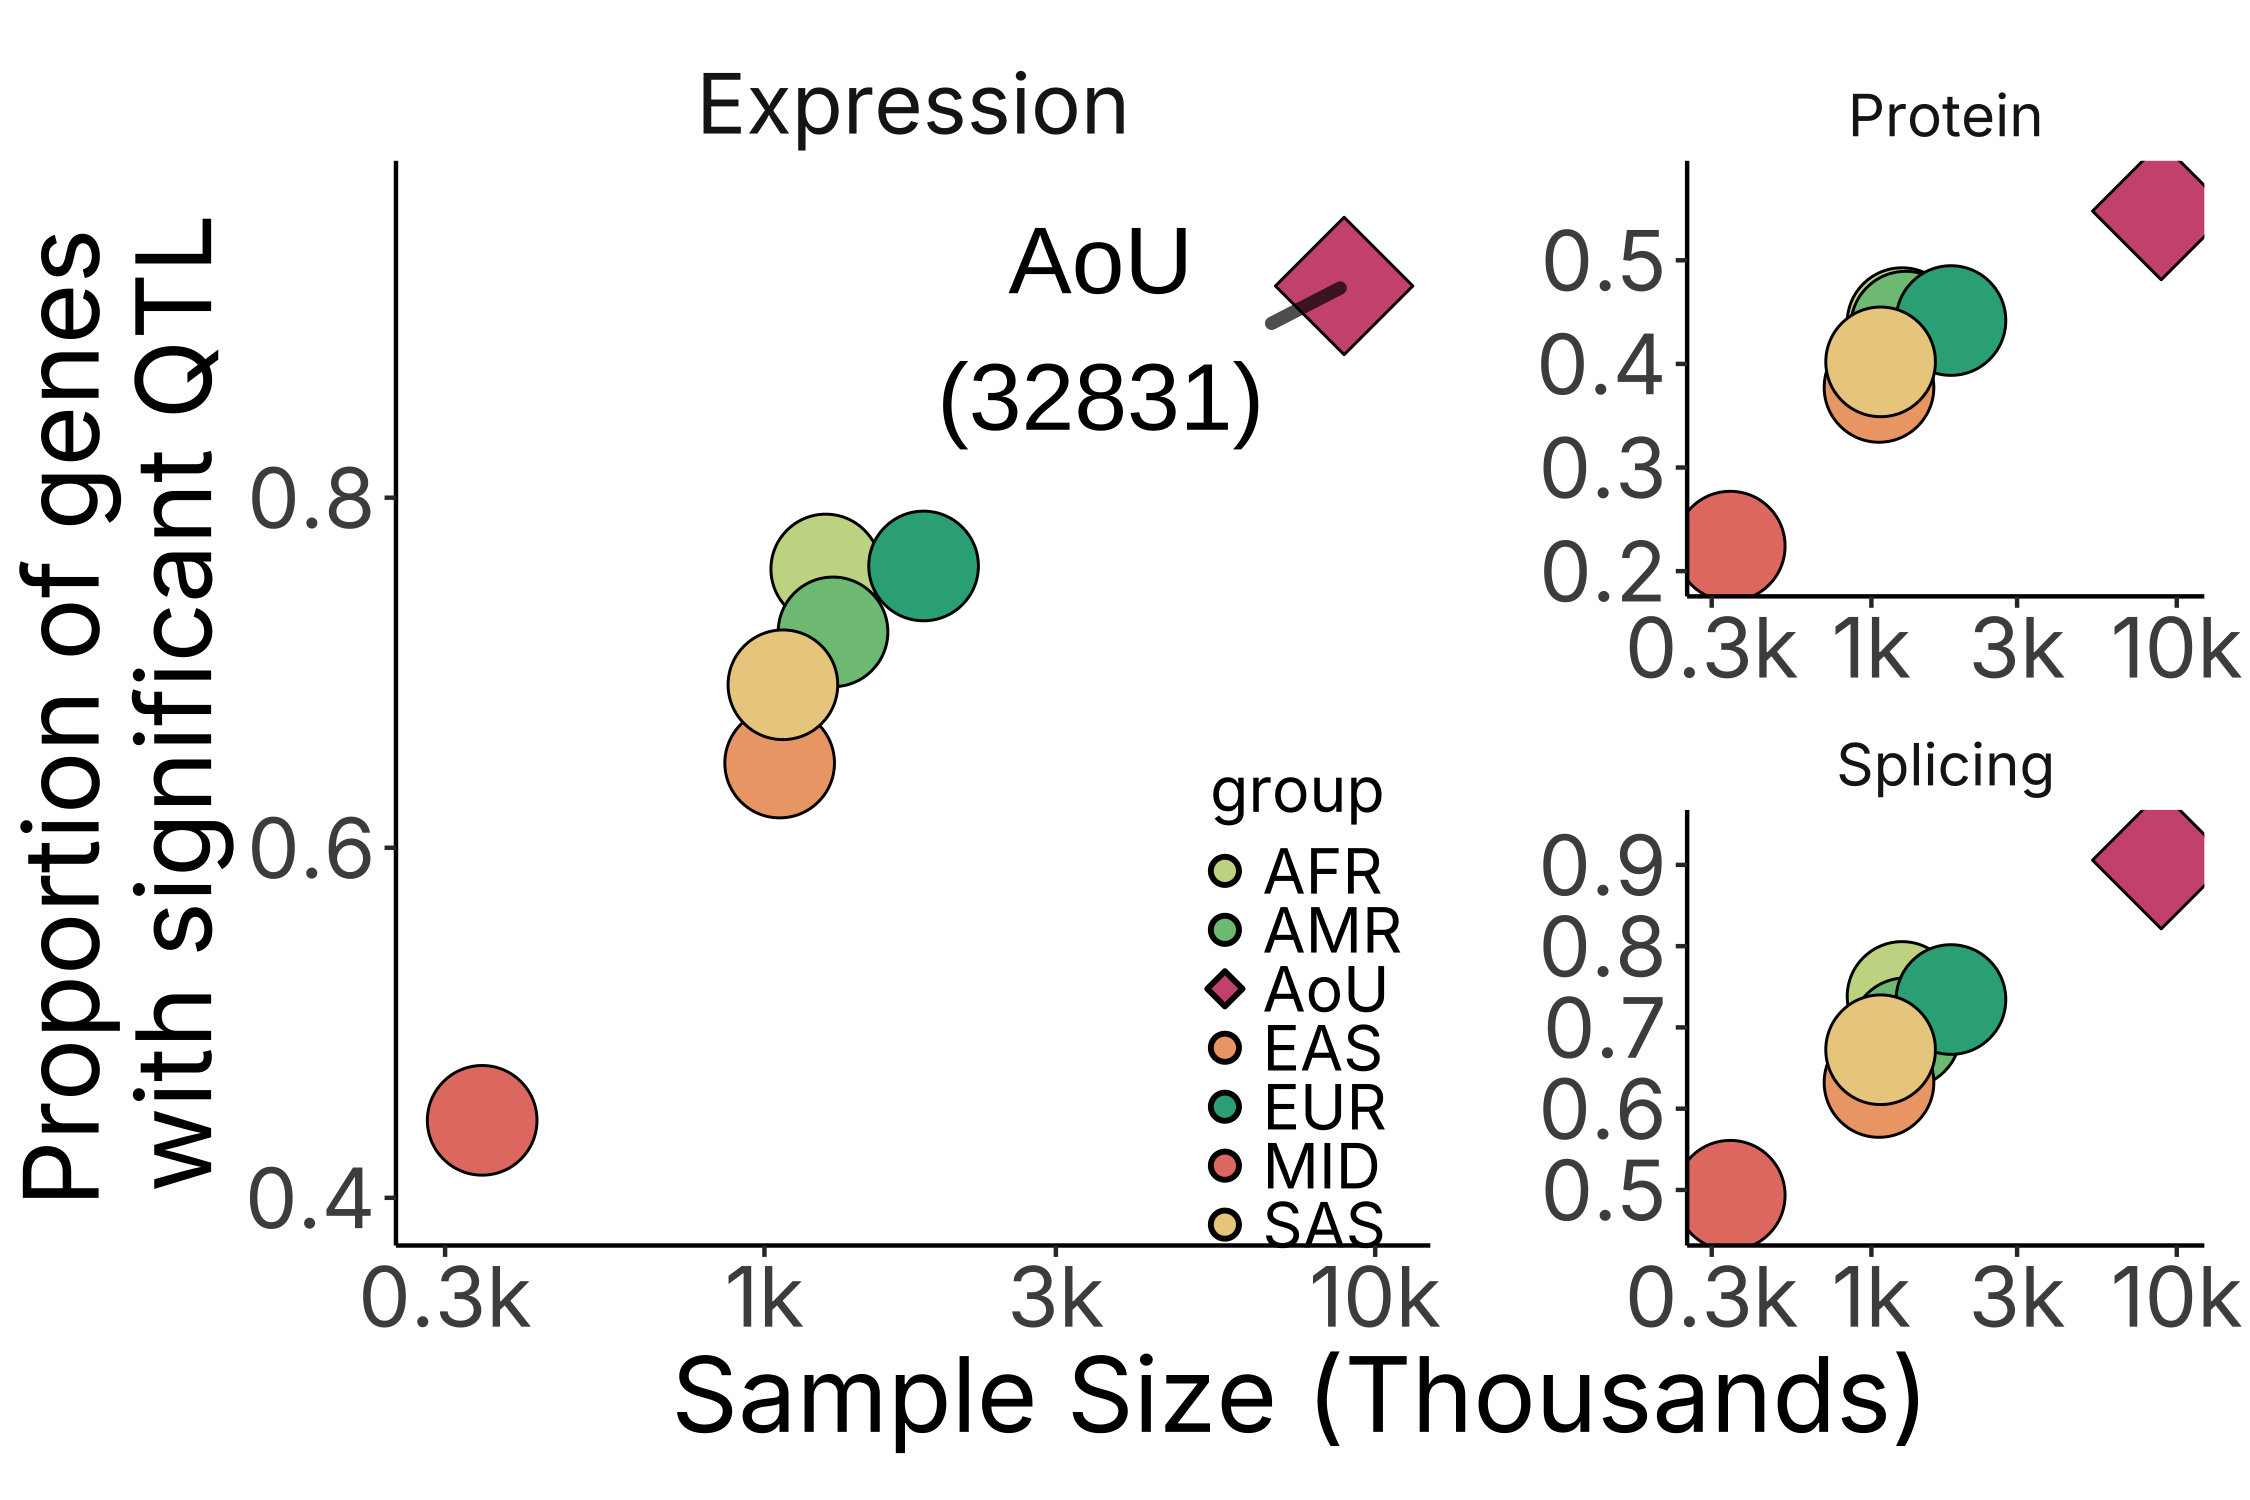

In [4]:
sample_ids <- fread(input_path("comb_sample_list"))$research_id
ancestry_counts <- LoadAncestryCounts(input_path("ancestry_preds"), sample_ids)

# FDR is per (ancestry, assay) — i.e. within each permutation file.
QTL_data <- load_input("perm") %>%
  group_by(group, Assay) %>%
  mutate(FDR = p.adjust(pval_beta, method = "fdr")) %>%
  ungroup()

combined_count <- sum(ancestry_counts$n)
prop_sig_data <- QTL_data %>%
  SummarizeSigQTLs(ancestry_counts) %>%
  left_join(AncestryColorPalette, by = c("group" = "Group")) %>%
  mutate(n = case_when(group == "AoU" ~ combined_count, TRUE ~ n))

add_aou_label <- function(df) {
  df %>% mutate(label = case_when(group == "AoU" ~ paste0("AoU", "\n(", num_sig, ")"), TRUE ~ group))
}
expression_only     <- prop_sig_data %>% filter(Assay == "Expression") %>% add_aou_label()
splicing_proteomics <- prop_sig_data %>% filter(Assay != "Expression") %>% add_aou_label()

expression_plot <- expression_only %>%
  PlotPropQTLSig() +
  theme(
    legend.text  = element_text(size = 15),
    legend.title = element_text(size = 15),
    panel.spacing = unit(2, "lines"),
    legend.position = c(0.88, 0.22),
    legend.key.size = unit(0.2, "cm"),
    plot.margin = margin(r = 20, unit = "pt")
  ) +
  ggrepel::geom_text_repel(
    data = subset(expression_only, Assay == "Expression" & group == "AoU"),
    aes(label = label),
    size = 8, force = 1000, nudge_x = -.4, nudge_y = -.025,
    segment.color = "black", segment.size = 1.5, segment.alpha = 0.7,
    min.segment.length = 0
  ) +
  guides(shape = guide_legend(override.aes = list(size = 2.5)))

splicing_proteomics_plot <- splicing_proteomics %>%
  PlotPropQTLSig() +
  theme(strip.text = element_text(size = 14),
        axis.title.y = element_blank(),
        plot.tag = element_blank()) +
  guides(fill = "none", shape = "none")

# Combined object: expression (tagged) beside splicing+protein (tag suppressed).
pC <- expression_plot + splicing_proteomics_plot +
  plot_layout(axis_titles = "collect", widths = c(2, 1))

saveRDS(pC, file.path(OBJ_DIR, "C.rds"))
message("Panel C built.")

pC


### Panel D — novel eGene + sGene + pGene counts vs external consortia

Counts eGenes / sGenes discovered here that are **novel** relative to GTEx, INTERVAL and TOPMed, broken down by gene type — what the *All of Us* cohort adds over prior consortia.

*Inputs: perm (COMB expression/splicing/protein), gene_gtf, external references,*


Panel D built.



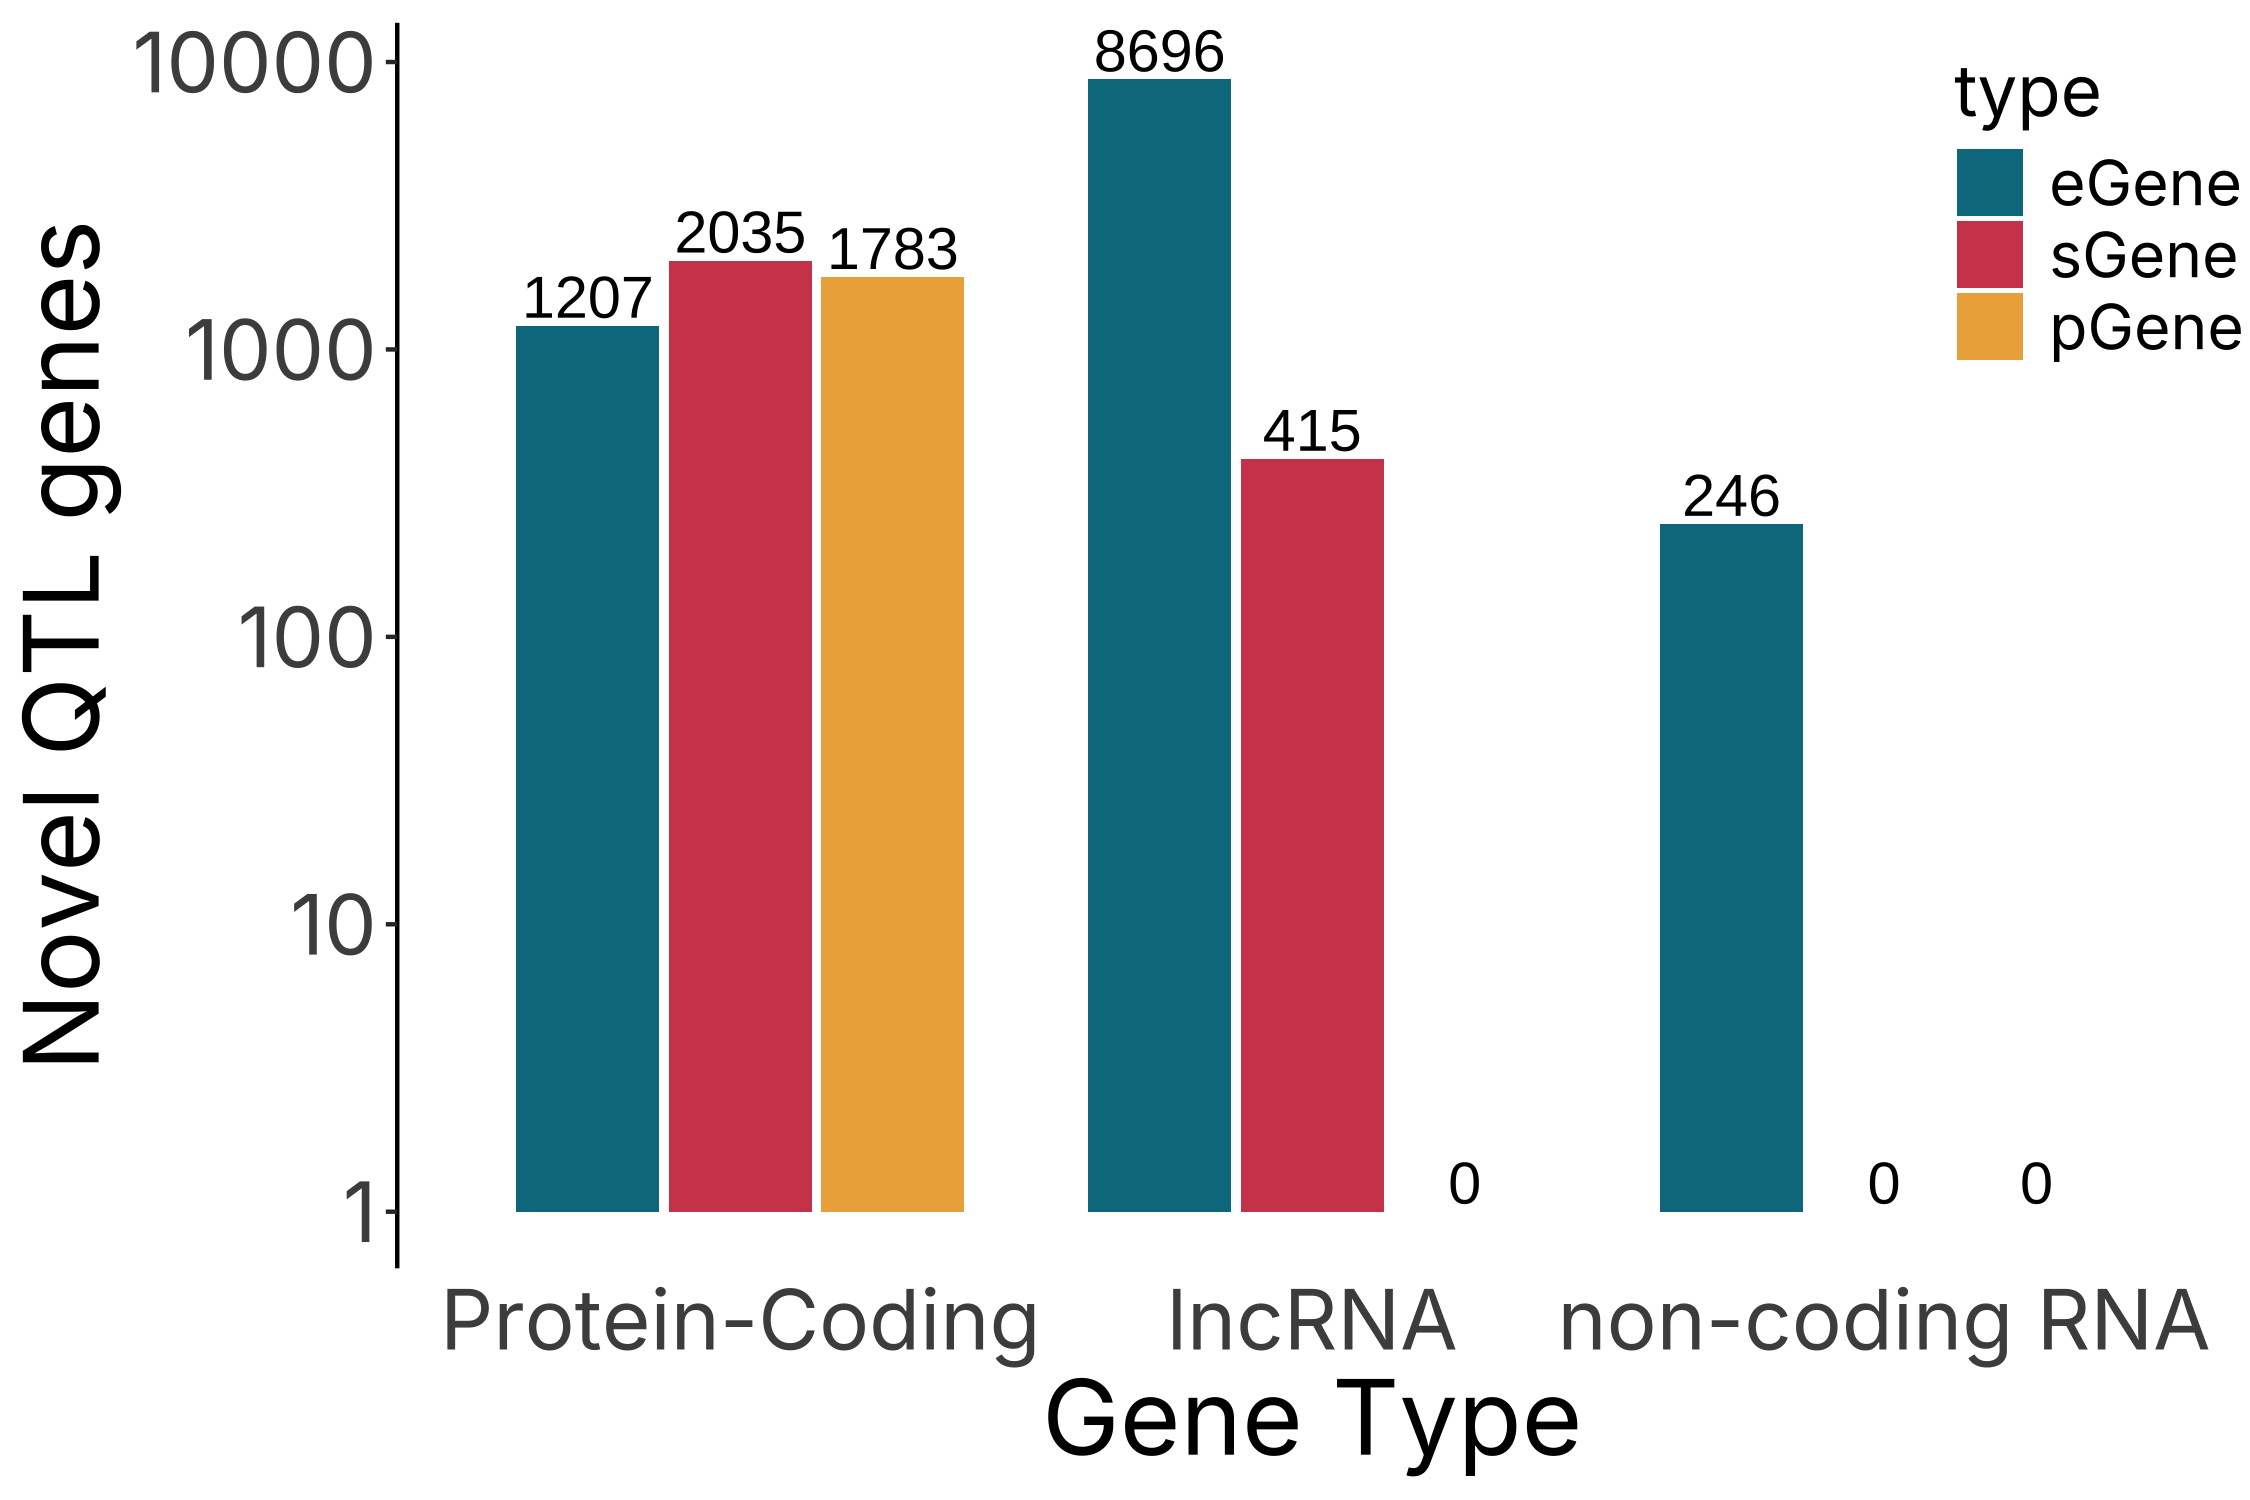

In [5]:
QTL_data <- load_input("perm")

gene_types <- import(input_path("gene_gtf")) %>% data.frame() %>%
  select(gene_id, gene_type) %>% distinct() %>%
  mutate(gene_id = str_remove(gene_id, "\\..*"))

ExternaleQTLs <- LoadExternaleQTLs(
  input_path("gtex_egenes"),
  input_path("interval_eqtl"),
  input_path("topmed_eqtl")
) %>% filter(Significant == TRUE)

ExternalsQTLs <- LoadExternalsQTLs(
  input_path("gtex_sgenes"),
  input_path("interval_sqtl")
) %>% filter(Significant == TRUE)

novel_eQTLs <- QTL_data %>%
  filter(group == "COMB" & Assay == "Expression") %>%
  mutate(phenotype_id = str_remove(phenotype_id, "\\..*")) %>%
  left_join(gene_types, by = c("phenotype_id" = "gene_id")) %>%
  filter(qval < .05) %>%
  ExtractNovelQTLs(ExternaleQTLs$gene_id) %>%
  mutate(type = "eGene")

novel_sQTLs <- QTL_data %>%
  filter(group == "COMB" & Assay == "Splicing") %>%
  mutate(phenotype_id = str_remove_all(phenotype_id, ".*:|\\..*")) %>%
  left_join(gene_types, by = c("phenotype_id" = "gene_id")) %>%
  filter(qval < .05) %>%
  ExtractNovelQTLs(ExternalsQTLs$gene_id) %>%
  mutate(type = "sGene")

# Novel pGenes vs the UKBB-PPP cis-pQTL reference. The original notebook
# referenced UKBB_pqtl_path but never assigned it, so this bar was silently
# absent; see NOTES.md. lncRNA is dropped because the proteomics assay cannot
# measure it, so a "novel lncRNA pGene" count would be an artefact of the join.
UKBB_pQTLs <- LoadUKBBpQTL(input_path("ukbb_pqtl"))

novel_pQTLs <- QTL_data %>%
  filter(group == "COMB" & Assay == "Protein") %>%
  filter(qval < .05) %>%
  mutate(phenotype_id = str_remove_all(phenotype_id, ".*_|\\..*")) %>%
  left_join(gene_types, by = c("phenotype_id" = "gene_id")) %>%
  ExtractNovelQTLs(UKBB_pQTLs$gene_id) %>%
  filter(group != "lncRNA") %>%
  mutate(type = "pGene")

gene_type_levels <- c("Protein-Coding", "lncRNA", "non-coding RNA")
type_levels      <- c("eGene", "sGene", "pGene")
novel_qtl_count <- bind_rows(novel_eQTLs, novel_sQTLs, novel_pQTLs) %>%
  mutate(group = factor(group, levels = gene_type_levels),
         type  = factor(type,  levels = type_levels)) %>%
  tidyr::complete(group, type, fill = list(count = 0)) %>%
  mutate(group = factor(group, levels = gene_type_levels),
         type  = factor(type,  levels = type_levels))

pD <- PlotNovelQTLCount(novel_qtl_count)

saveRDS(pD, file.path(OBJ_DIR, "D.rds"))
message("Panel D built.")

pD


### Panel E — CDF of credible sets per eGene (COMB)

Builds the cumulative distribution of the number of SuSiE credible sets per eGene (fraction of eGenes with ≥ *k* credible sets), summarizing the allelic complexity of expression regulation.

*Inputs: finemap_eqtl (all ancestries)*


`summarise()` has grouped output by 'group', 'Assay'. You can override using
the `.groups` argument.


Panel E built.



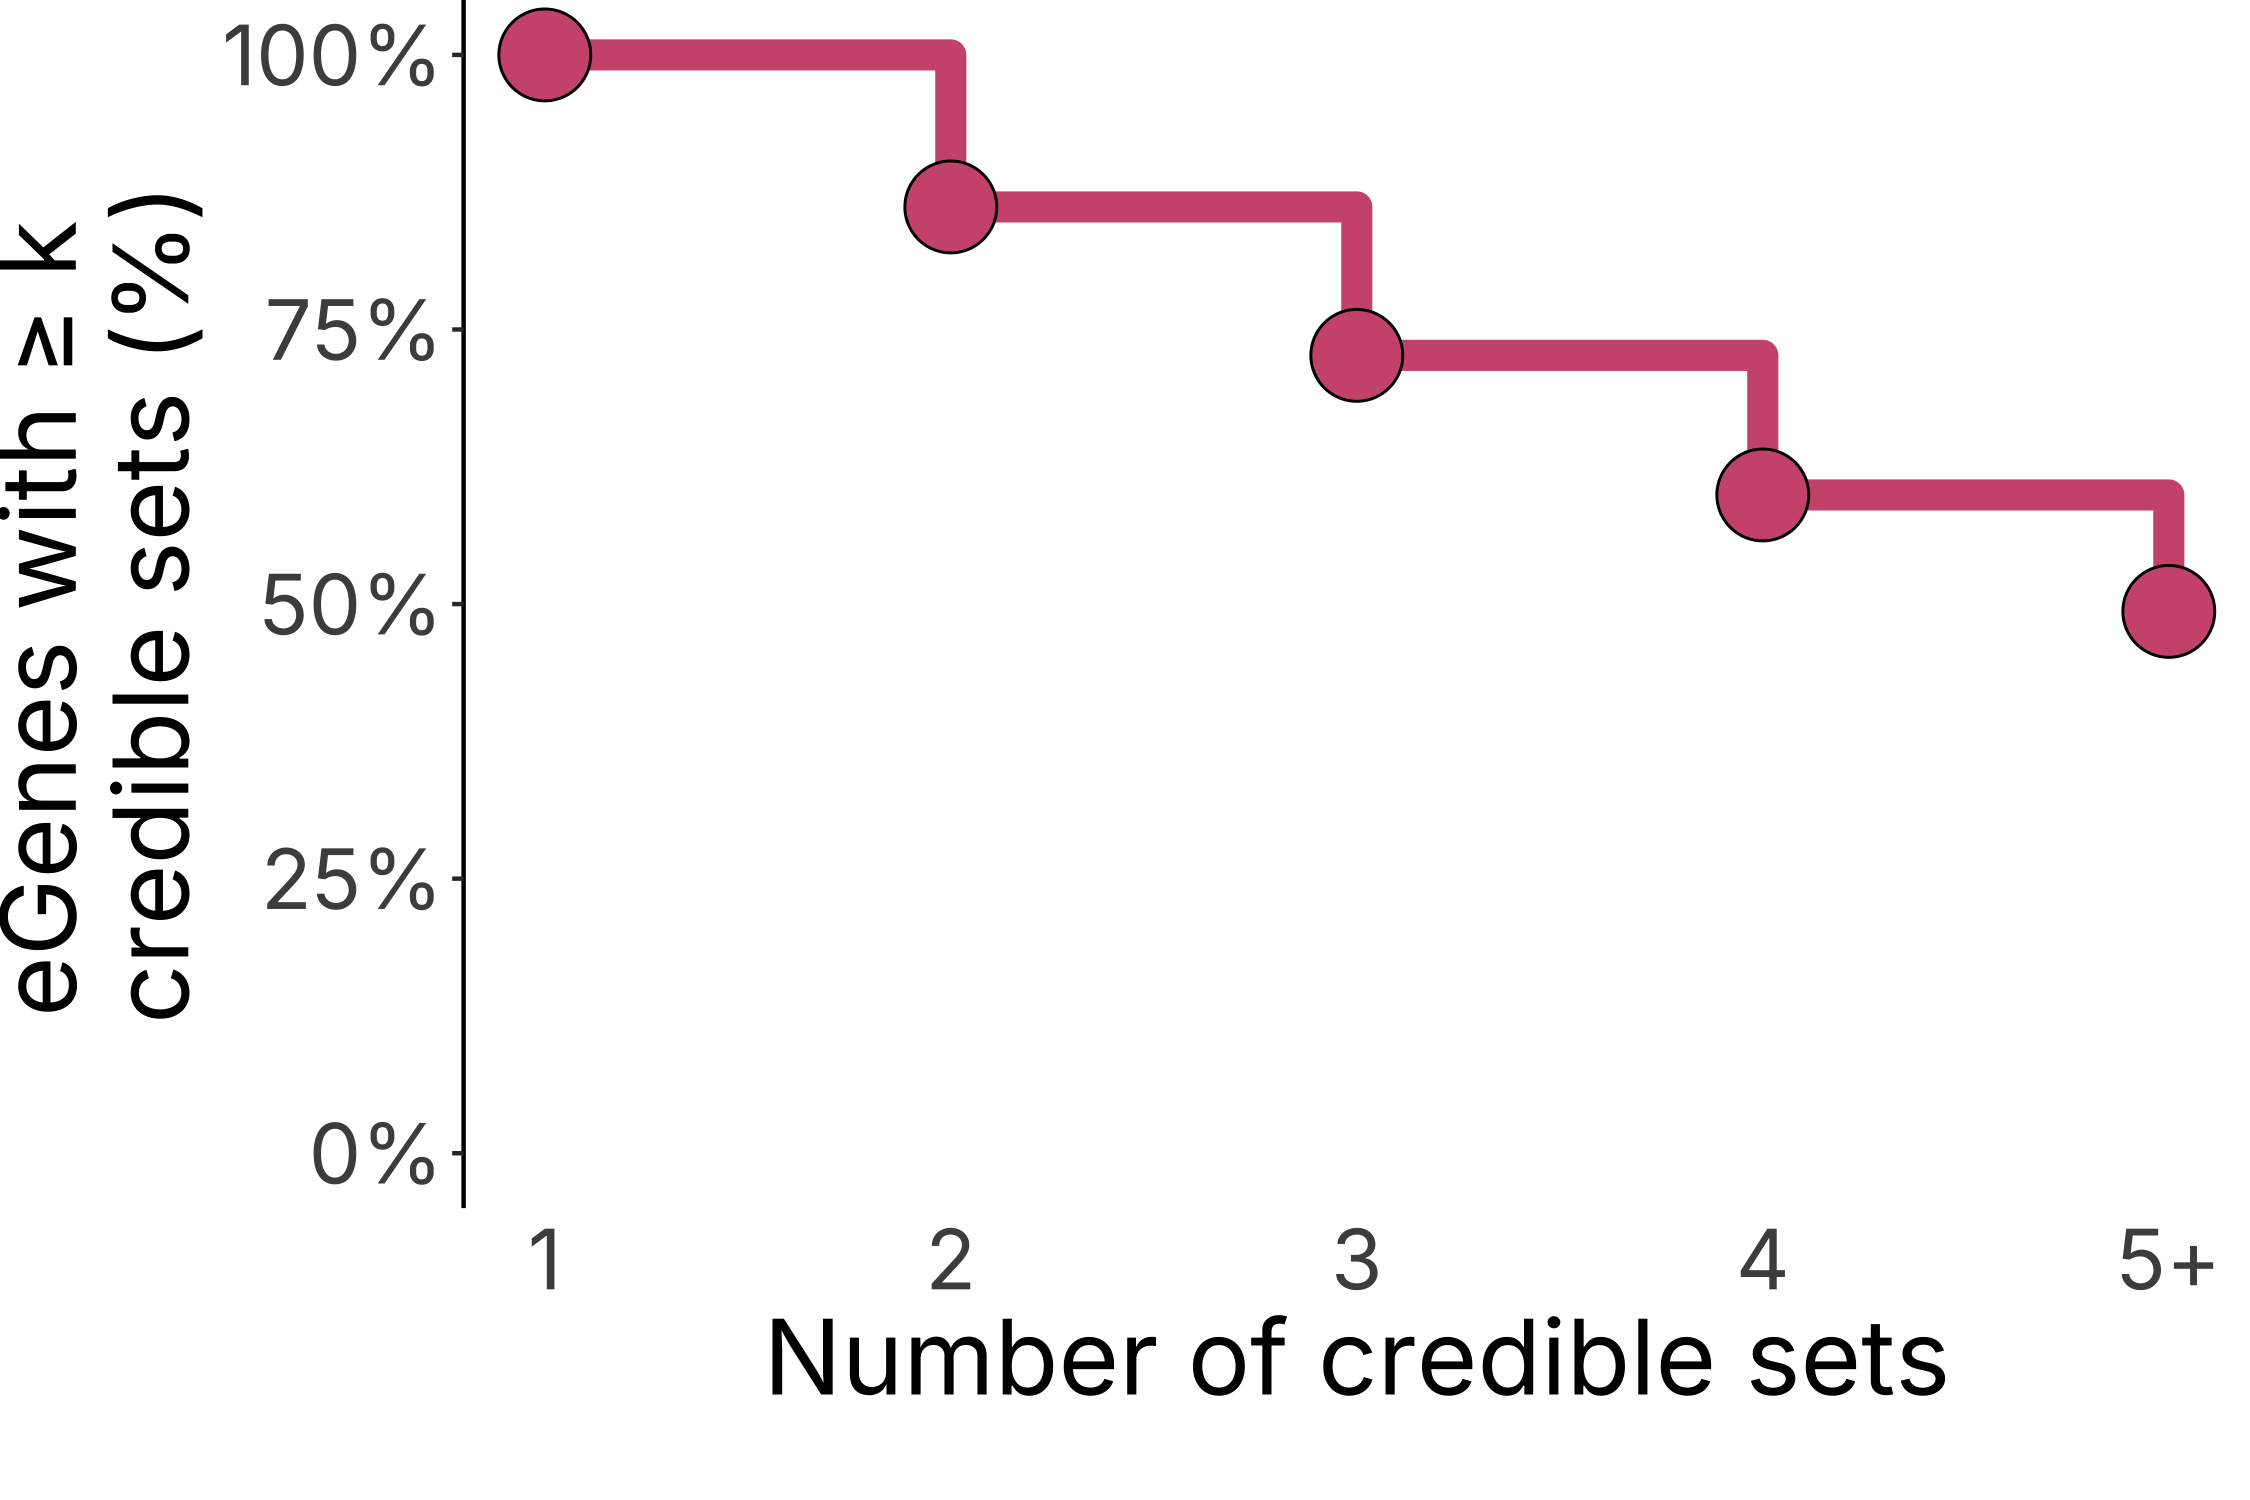

In [6]:
eQTL_finemapping <- load_input("finemap_eqtl")
eQTL_cs_number <- eQTL_finemapping %>%
  distinct(molecular_trait_id, cs_id, group, Assay)
ccdf <- ComputeCredibleSetCDF(eQTL_cs_number)

pE <- ccdf %>%
  filter(number_cs > 0, group == "COMB", number_cs <= 5) %>%
  ggplot(aes(y = prop_ge, x = number_cs)) +
    geom_step(color = "#CF597E", lwd = 3.5) +
    geom_point(shape = 21, size = 10, fill = "#CF597E") +
    scale_x_continuous(breaks = 1:5, labels = c("1", "2", "3", "4", "5+")) +
    scale_y_continuous(labels = scales::percent_format(accuracy = 1), limits = c(0, 1)) +
    theme(
      plot.margin = margin(b = 20, unit = "pt"),
      axis.line.x = element_blank(),
      axis.ticks.x = element_blank()
    ) +
    labs(x = "Number of credible sets",
         y = "eGenes with ≥ k \ncredible sets (%)")

saveRDS(pE, file.path(OBJ_DIR, "E.rds"))
message("Panel E built.")

pE


### Panel F — credible-set sizes across pQTL ancestry groups (+ UKBB reference point)

Compares credible-set sizes across pQTL ancestry groups, with a UKBB reference point — a readout of fine-mapping resolution for proteins.

*Inputs: finemap_pqtl*


Panel F built.



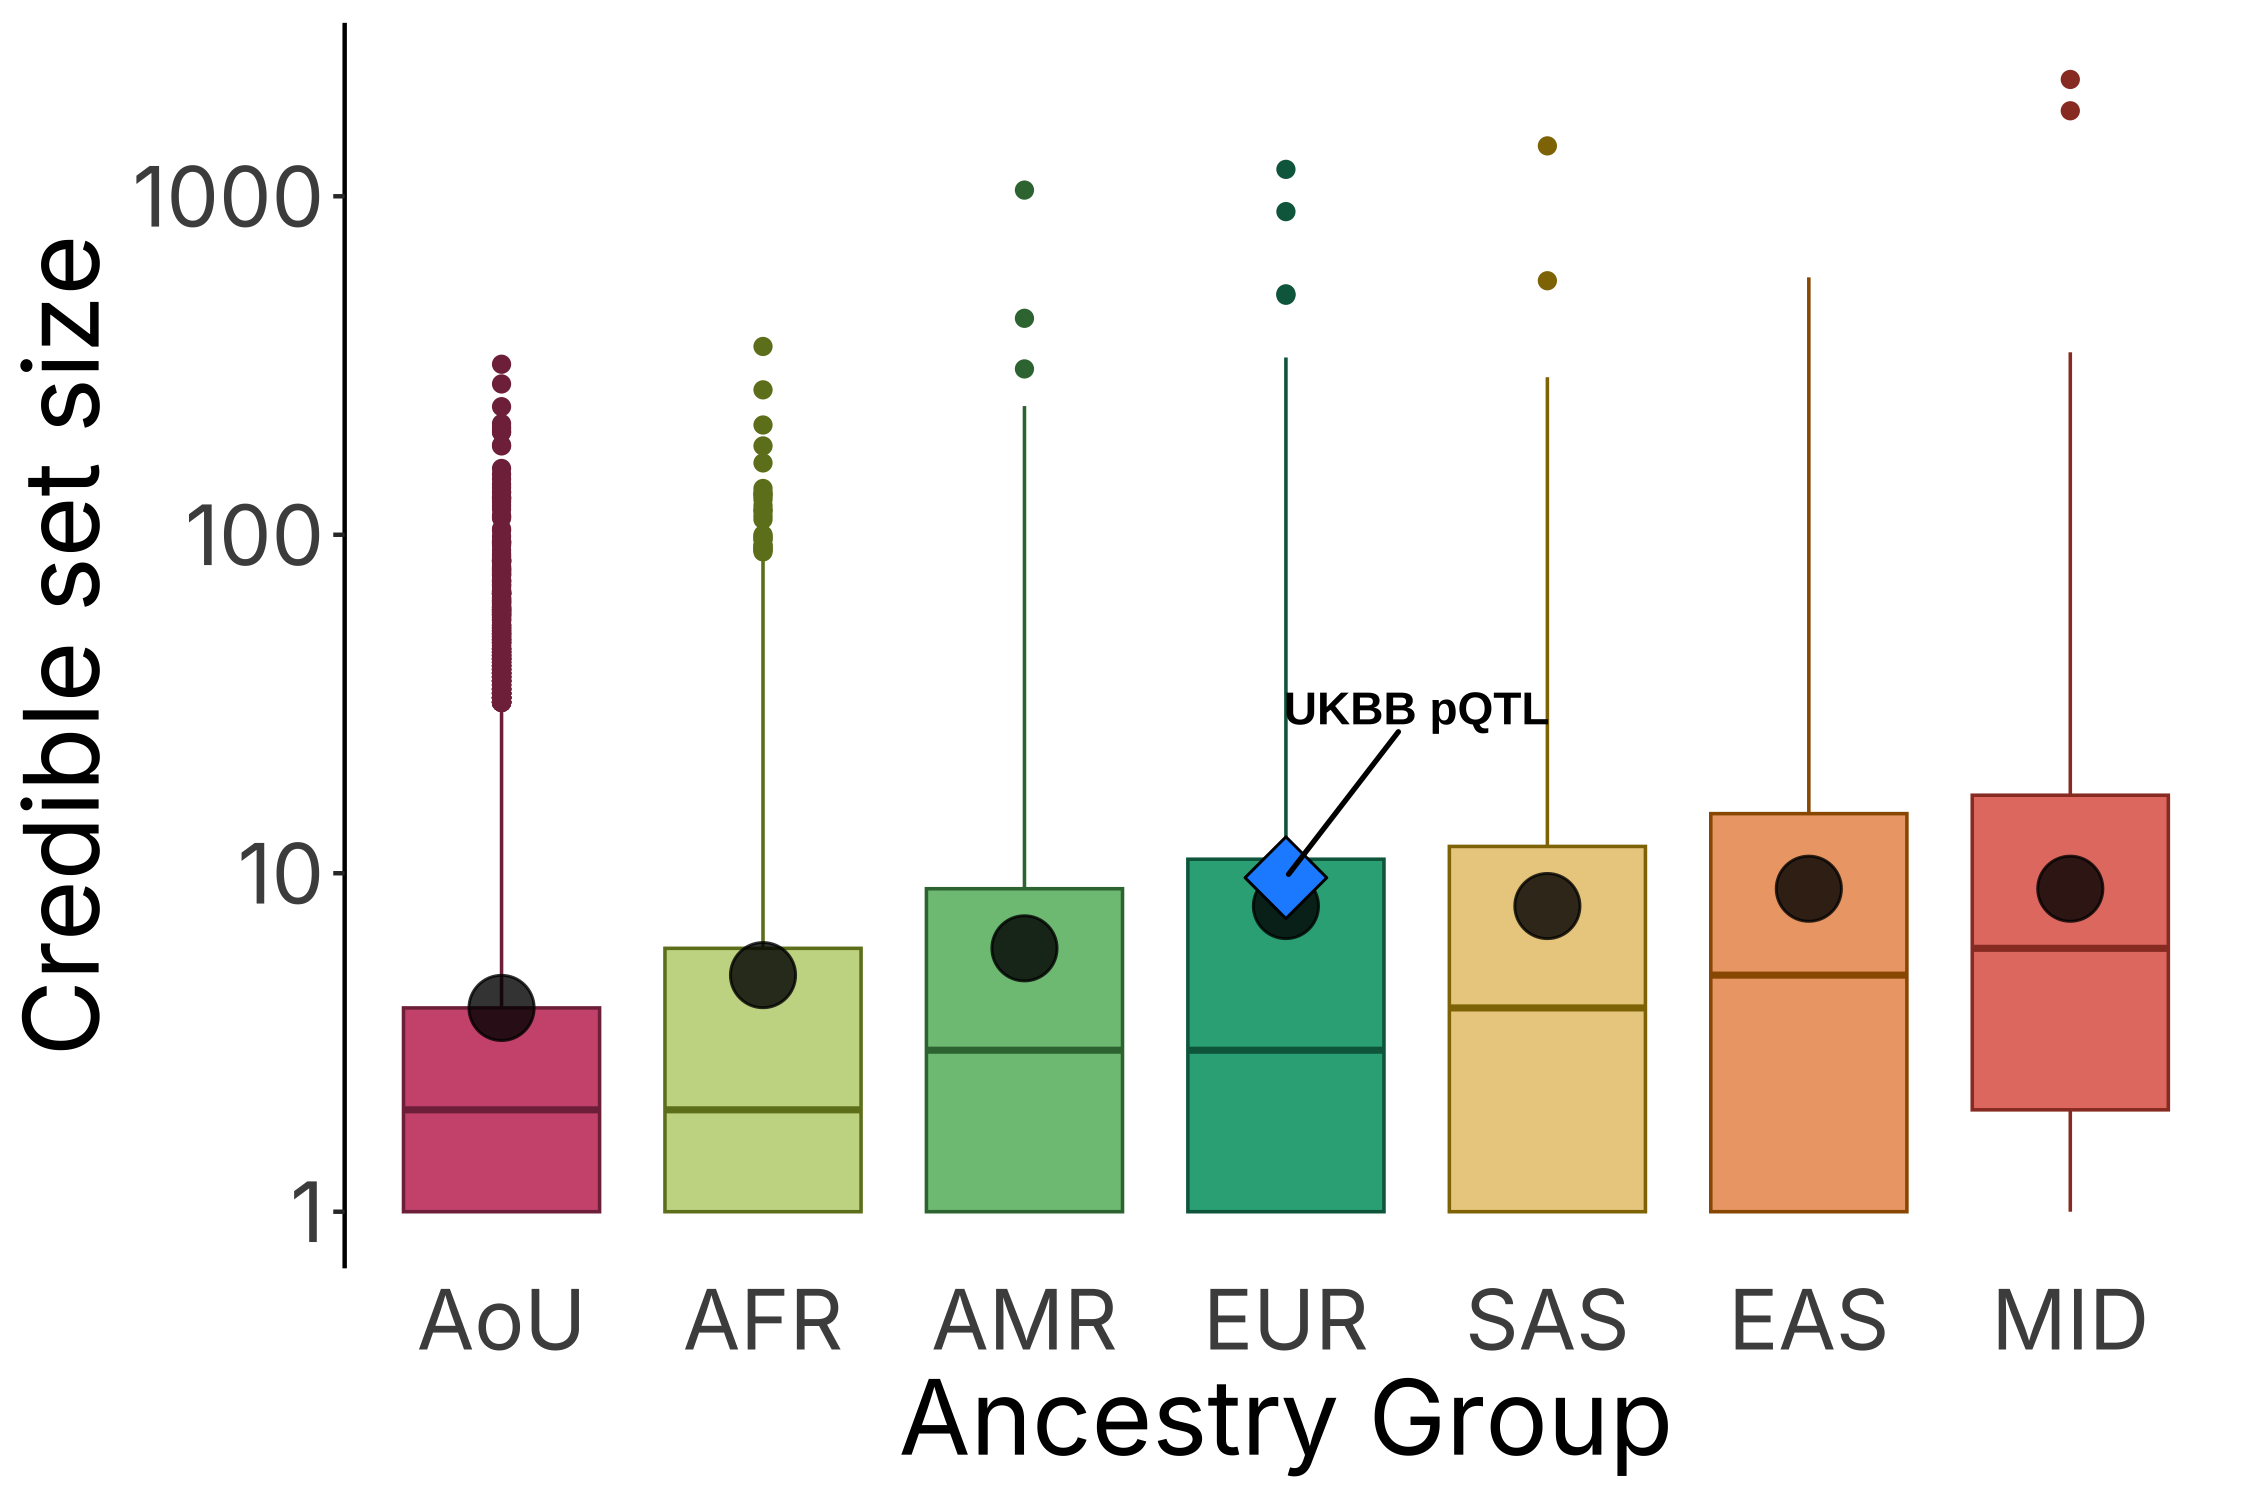

In [7]:
pQTL_susie <- load_input("finemap_pqtl")

ref_means <- data.frame(group = "EUR", mean_cs = 9.7)   # UKBB pQTL reference average
pQTL_cs_sizes <- pQTL_susie %>%
  distinct(cs_id, cs_size, group, Assay)
common_var_means <- pQTL_susie %>%
  filter(!ALT_FREQS < .01 & !cs_size == 1) %>%
  distinct(cs_id, cs_size, group, Assay) %>%
  group_by(group) %>%
  summarize(mean_cs = median(cs_size)) %>%
  mutate(group = case_when(group == "COMB" ~ "AoU", TRUE ~ group))

pF <- pQTL_cs_sizes %>%
  PlotCSSizes(AncestryColorPalette) +
  # Black point: median credible-set size over common variants (>=1% AF, size > 1).
  geom_point(data = common_var_means, aes(x = group, y = mean_cs),
             shape = 21, fill = "black", size = 7, color = "black",
             show.legend = FALSE, alpha = 0.8) +
  # Diamond: external UKBB pQTL reference average.
  geom_point(data = ref_means, aes(x = group, y = mean_cs),
             shape = 23, size = 7, fill = "dodgerblue", color = "black") +
  geom_text_repel(inherit.aes = FALSE, data = ref_means,
                  aes(x = group, y = mean_cs), label = "UKBB pQTL",
                  nudge_y = 0.5, nudge_x = 0.5, color = "black", fontface = "bold",
                  segment.color = "black", segment.size = 0.6) +
  theme(axis.line.x = element_blank(), axis.ticks.x = element_blank())

saveRDS(pF, file.path(OBJ_DIR, "F.rds"))
message("Panel F built.")

pF


### Panel G — proportion of credible sets with a single causal variant (COMB)

Per assay, the proportion of credible sets resolved to a **single** causal variant — a direct comparison of fine-mapping resolution across expression, protein and splicing.

*Inputs: finemap_eqtl, finemap_pqtl, finemap_sqtl*


Panel G built.



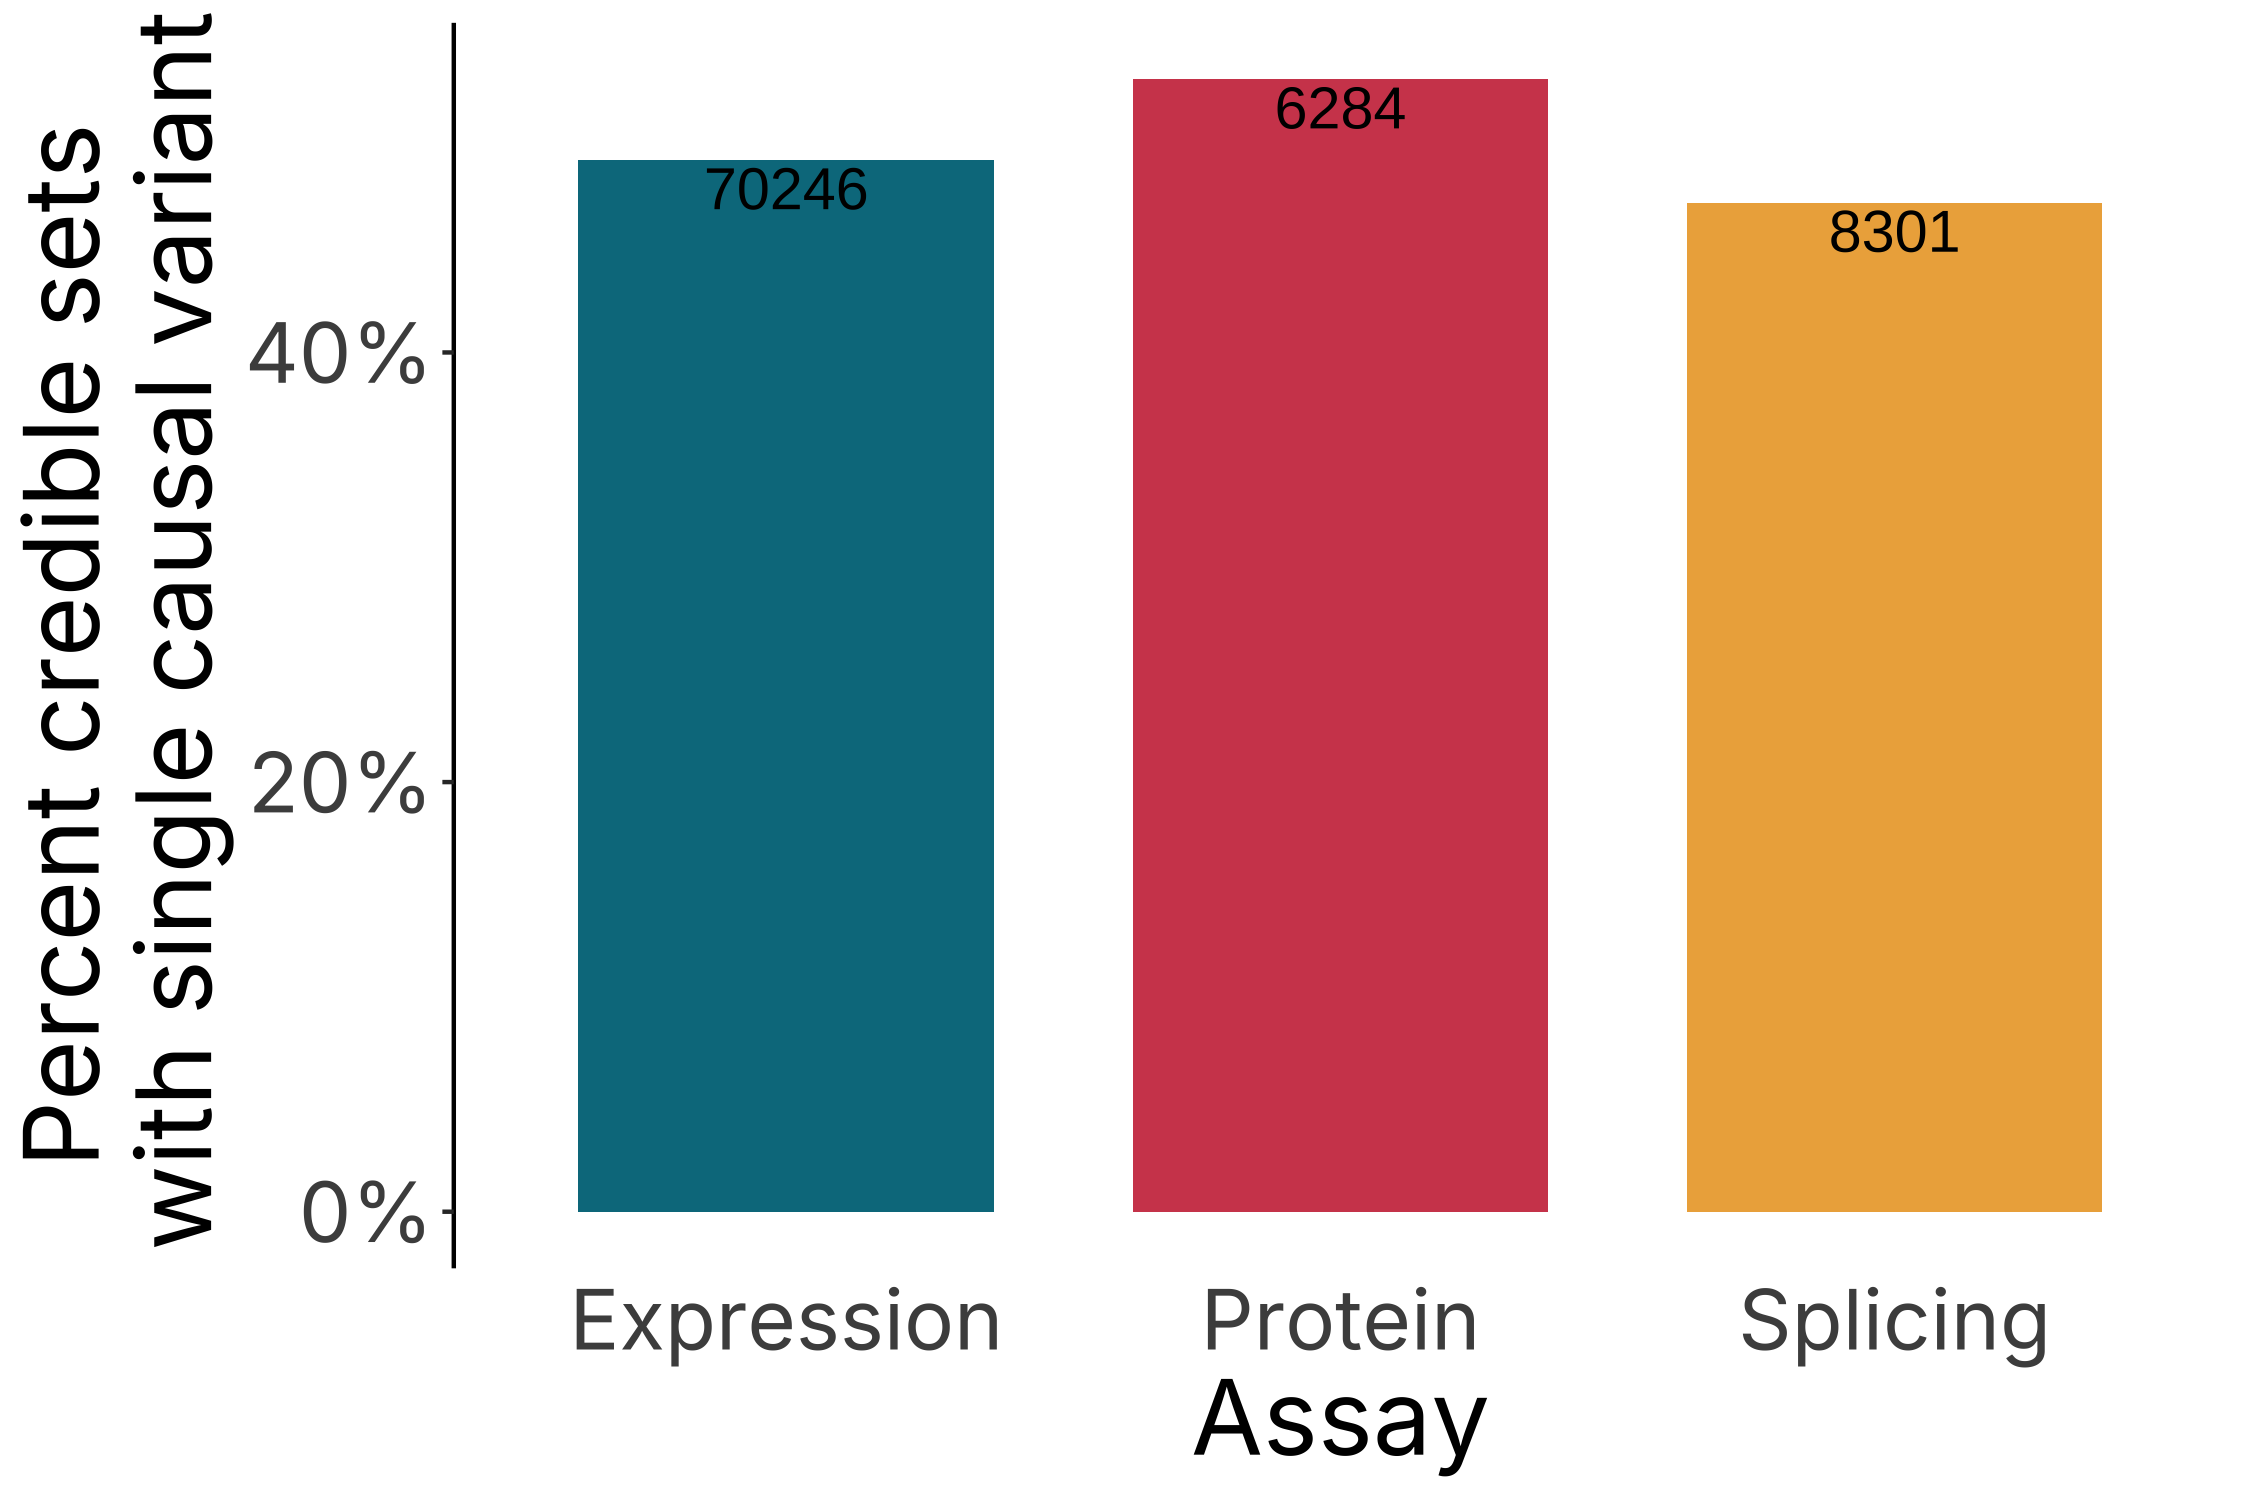

In [8]:
finemapping_cs <- bind_rows(
  load_input("finemap_eqtl") %>% select(group, pip, Assay, cs_id),
  load_input("finemap_pqtl") %>% select(group, pip, Assay, cs_id),
  load_input("finemap_sqtl") %>% select(group, pip, Assay, cs_id)
)

summary_data <- finemapping_cs %>%
  distinct(cs_id, group, Assay) %>%
  dplyr::count(Assay, group) %>%
  dplyr::rename("num_cs" = "n")
causal_variant_count <- finemapping_cs %>%
  filter(pip > 0.9) %>%
  distinct(cs_id, group, Assay) %>%
  dplyr::count(Assay, group) %>%
  dplyr::rename("number_causal" = "n")

pG <- summary_data %>%
  filter(group == "COMB") %>%
  left_join(causal_variant_count, by = c("Assay", "group")) %>%
  mutate(proportion_single = number_causal / num_cs) %>%
  mutate(Assay = factor(Assay, levels = c("Expression", "Protein", "Splicing"))) %>%
  ggplot(aes(x = Assay, y = proportion_single, fill = Assay)) +
    geom_col(show.legend = FALSE, width = 0.75, lwd = .2) +
    paletteer::scale_fill_paletteer_d("ltc::minou") +
    xlab("Assay") +
    theme(legend.position = "none",
          axis.ticks.x = element_blank(),
          axis.line.x = element_blank()) +
    geom_text(aes(label = number_causal), vjust = 1.2, show.legend = FALSE,
              color = "black", size = 5) +
    ylab("Percent credible sets\n with single causal variant") +
    scale_y_continuous(labels = scales::percent_format(accuracy = 1))

saveRDS(pG, file.path(OBJ_DIR, "G.rds"))
message("Panel G built.")

pG


### Panel H — fine-mapping functional enrichment by assay

Functional enrichment of fine-mapped causal variants across regulatory / coding annotation groups, per assay, testing where causal variants concentrate.

*Inputs: annot (COMB annotated SuSiE tables for eQTL / sQTL / pQTL)*


Panel H built.



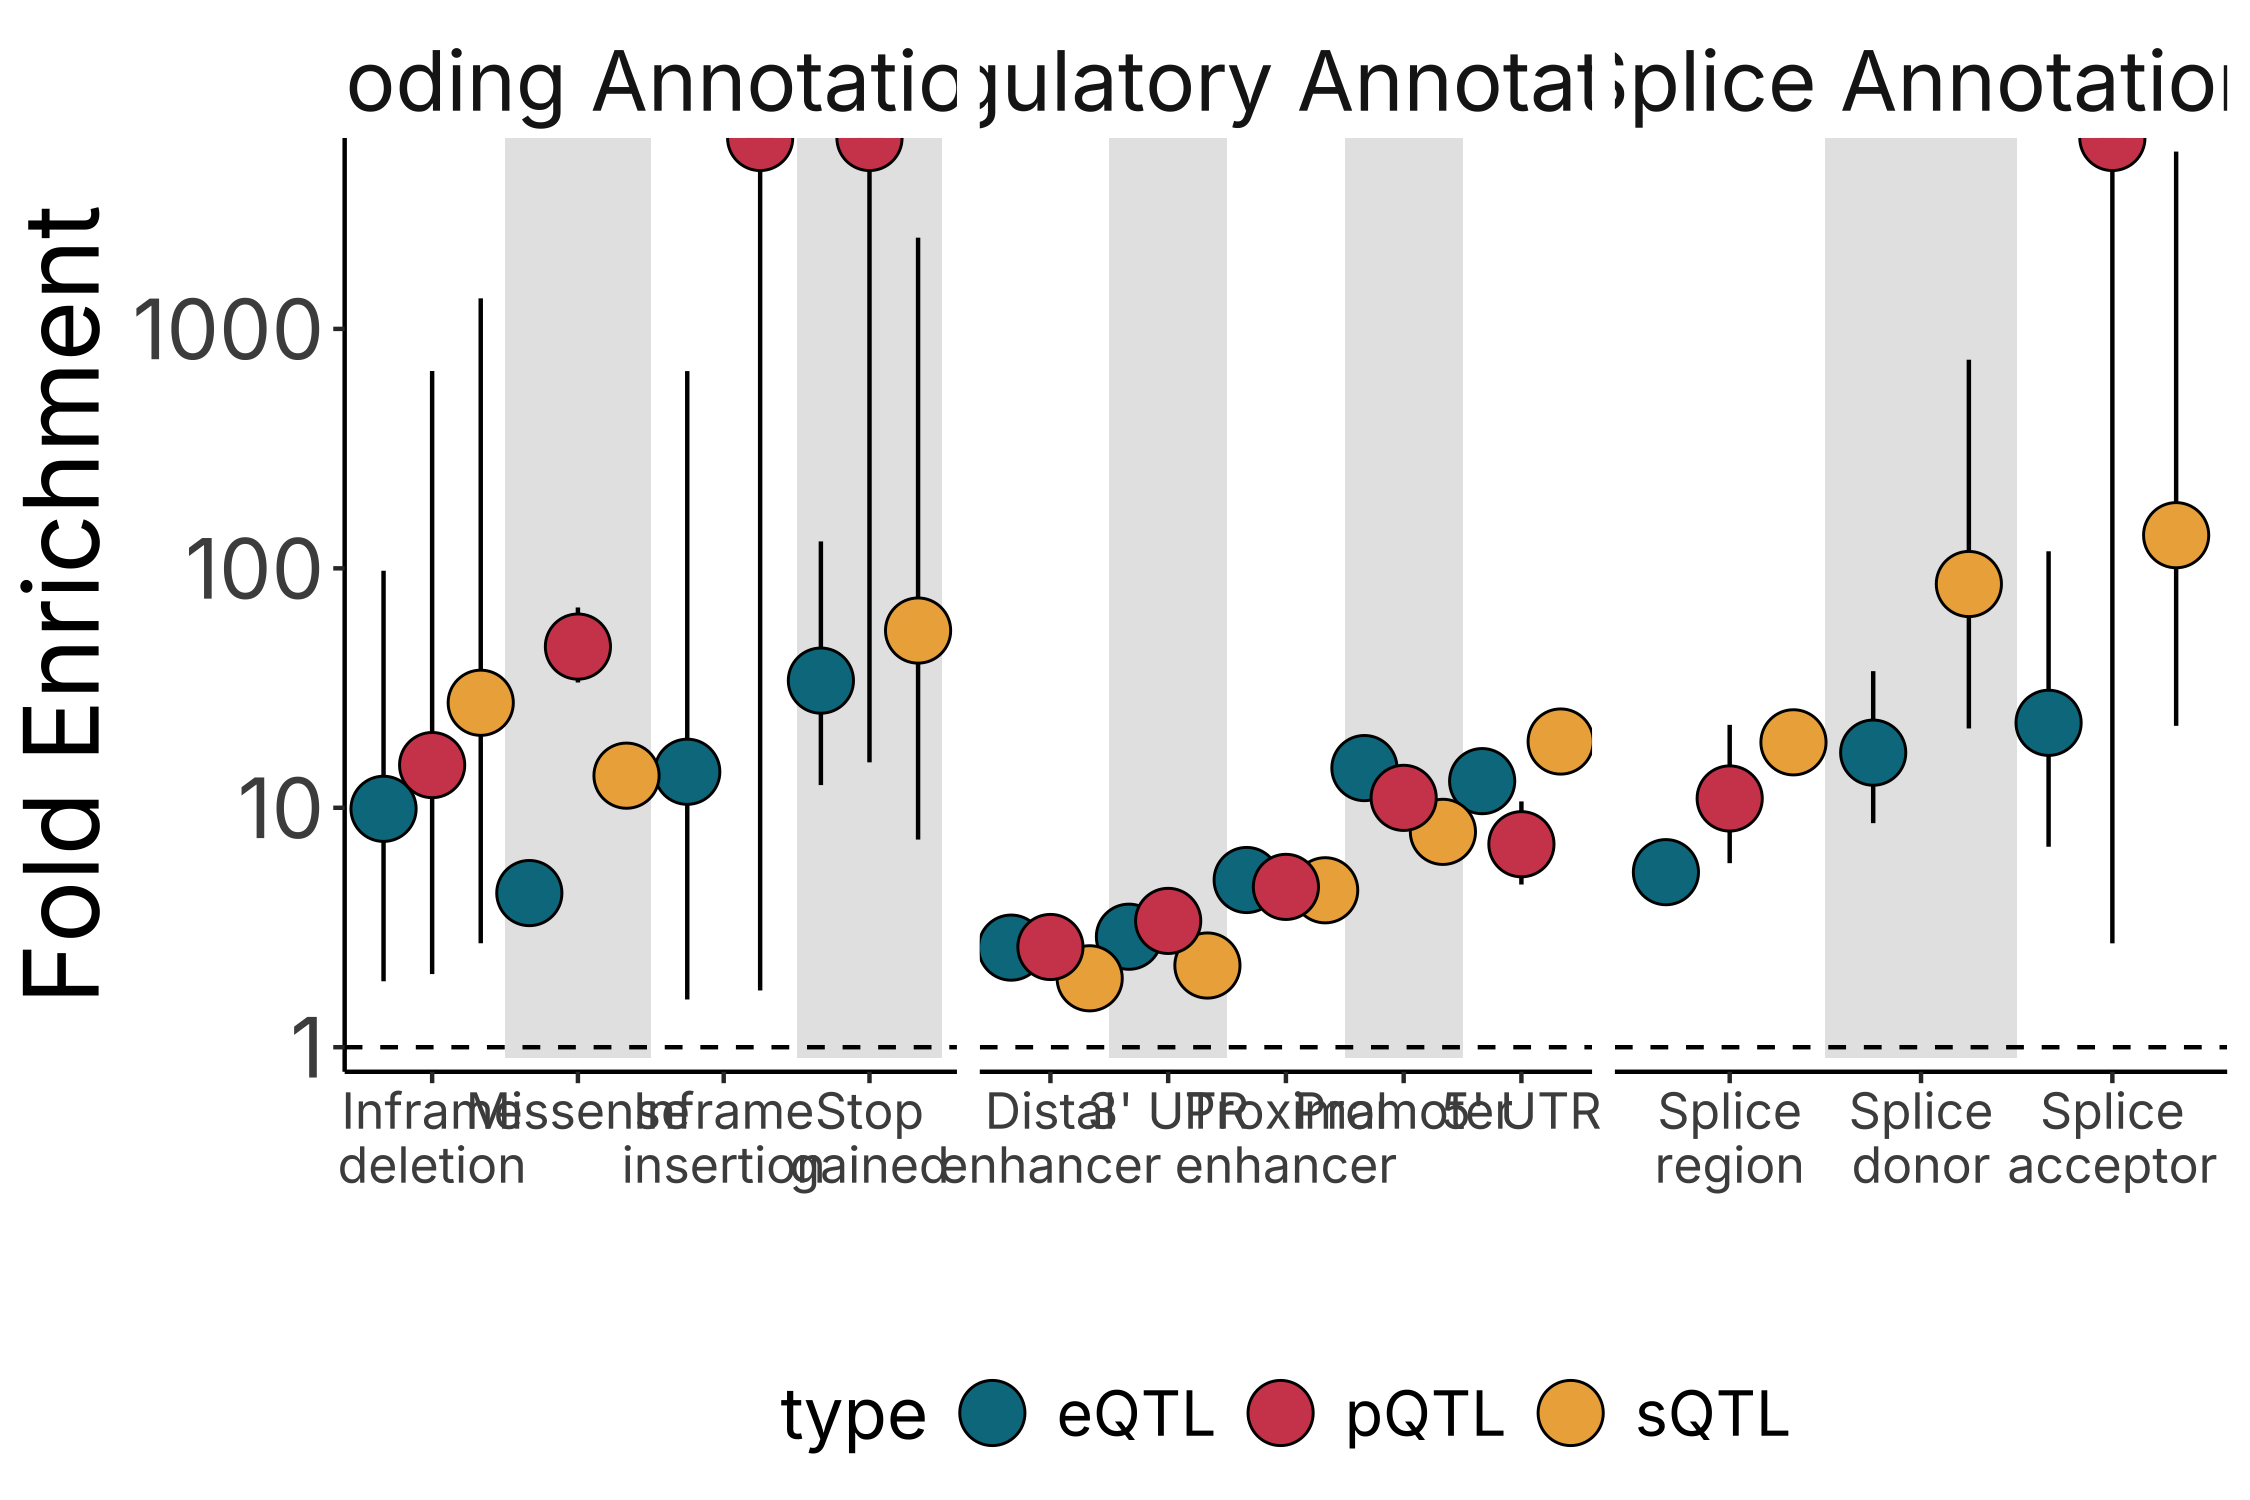

In [9]:
# One enrichment computation per annotated table, labelled by its assay/type.
annot <- input_files("annot")
QTLFinemappingEnrichments <- purrr::pmap_dfr(
  list(annot$path, annot$Assay),
  function(p, ty) fread(p) %>% ComputeFinemappingAnnotationEnrichment() %>% mutate(type = ty)
)

# Names must match VEP's own spelling exactly (3_prime_UTR_variant, not
# _utr_): these are matched by an equality join, so a casing difference
# silently drops the annotation rather than erroring.
variant_functional_groups <- tibble::tribble(
  ~name, ~functional_group,
  # UTR
  "3_prime_UTR_variant", "Regulatory Annotation",
  "5_prime_UTR_variant", "Regulatory Annotation",
  # Regulatory elements
  "CTCF.bound", "Regulatory Annotation",
  "DNase.H3K4me3", "Regulatory Annotation",
  "FANTOM5", "Regulatory Annotation",
  "PLS", "Regulatory Annotation",
  "pELS", "Regulatory Annotation",
  "dELS", "Regulatory Annotation",
  # Coding
  "coding_sequence_variant", "Coding Annotation",
  "frameshift_variant", "Coding Annotation",
  "inframe_deletion", "Coding Annotation",
  "inframe_insertion", "Coding Annotation",
  "missense_variant", "Coding Annotation",
  "synonymous_variant", "Coding Annotation",
  "start_lost", "Coding Annotation",
  "stop_gained", "Coding Annotation",
  "stop_lost", "Coding Annotation",
  "stop_retained_variant", "Coding Annotation",
  # Splice
  "splice_acceptor_variant", "Splice Annotation",
  "splice_donor_variant", "Splice Annotation",
  "splice_donor_5th_base_variant", "Splice Annotation",
  "splice_donor_region_variant", "Splice Annotation",
  "splice_region_variant", "Splice Annotation",
  "splice_polypyrimidine_tract_variant", "Splice Annotation",
  # Noncoding RNA
  "non_coding_transcript_exon_variant", "Noncoding RNA",
  "non_coding_transcript_variant", "Noncoding RNA",
  "mature_miRNA_variant", "Noncoding RNA",
  # Gene proximity / background
  "downstream_gene_variant", "Intronic/Intergenic",
  "upstream_gene_variant", "Intronic/Intergenic",
  "intron_variant", "Intronic/Intergenic",
  "intergenic_variant", "Intronic/Intergenic"
)

pH <- PlotFinemappingEnrichment(QTLFinemappingEnrichments, variant_functional_groups)

saveRDS(pH, file.path(OBJ_DIR, "H.rds"))
message("Panel H built.")

pH


## Assemble the figure

Loads the cached panel objects from `Fig1/objects/` and composes them with patchwork into the final figure. Panel **tagging happens here and only here**. Writes the PDF plus a PNG preview, and renders the assembled figure inline.


Warning message:
“Duplicated `override.aes` is ignored.”


Warning message:
“Duplicated `override.aes` is ignored.”


Assembled: fig1/Figure1.pdf and Figure1.png



Warning message:
“Duplicated `override.aes` is ignored.”


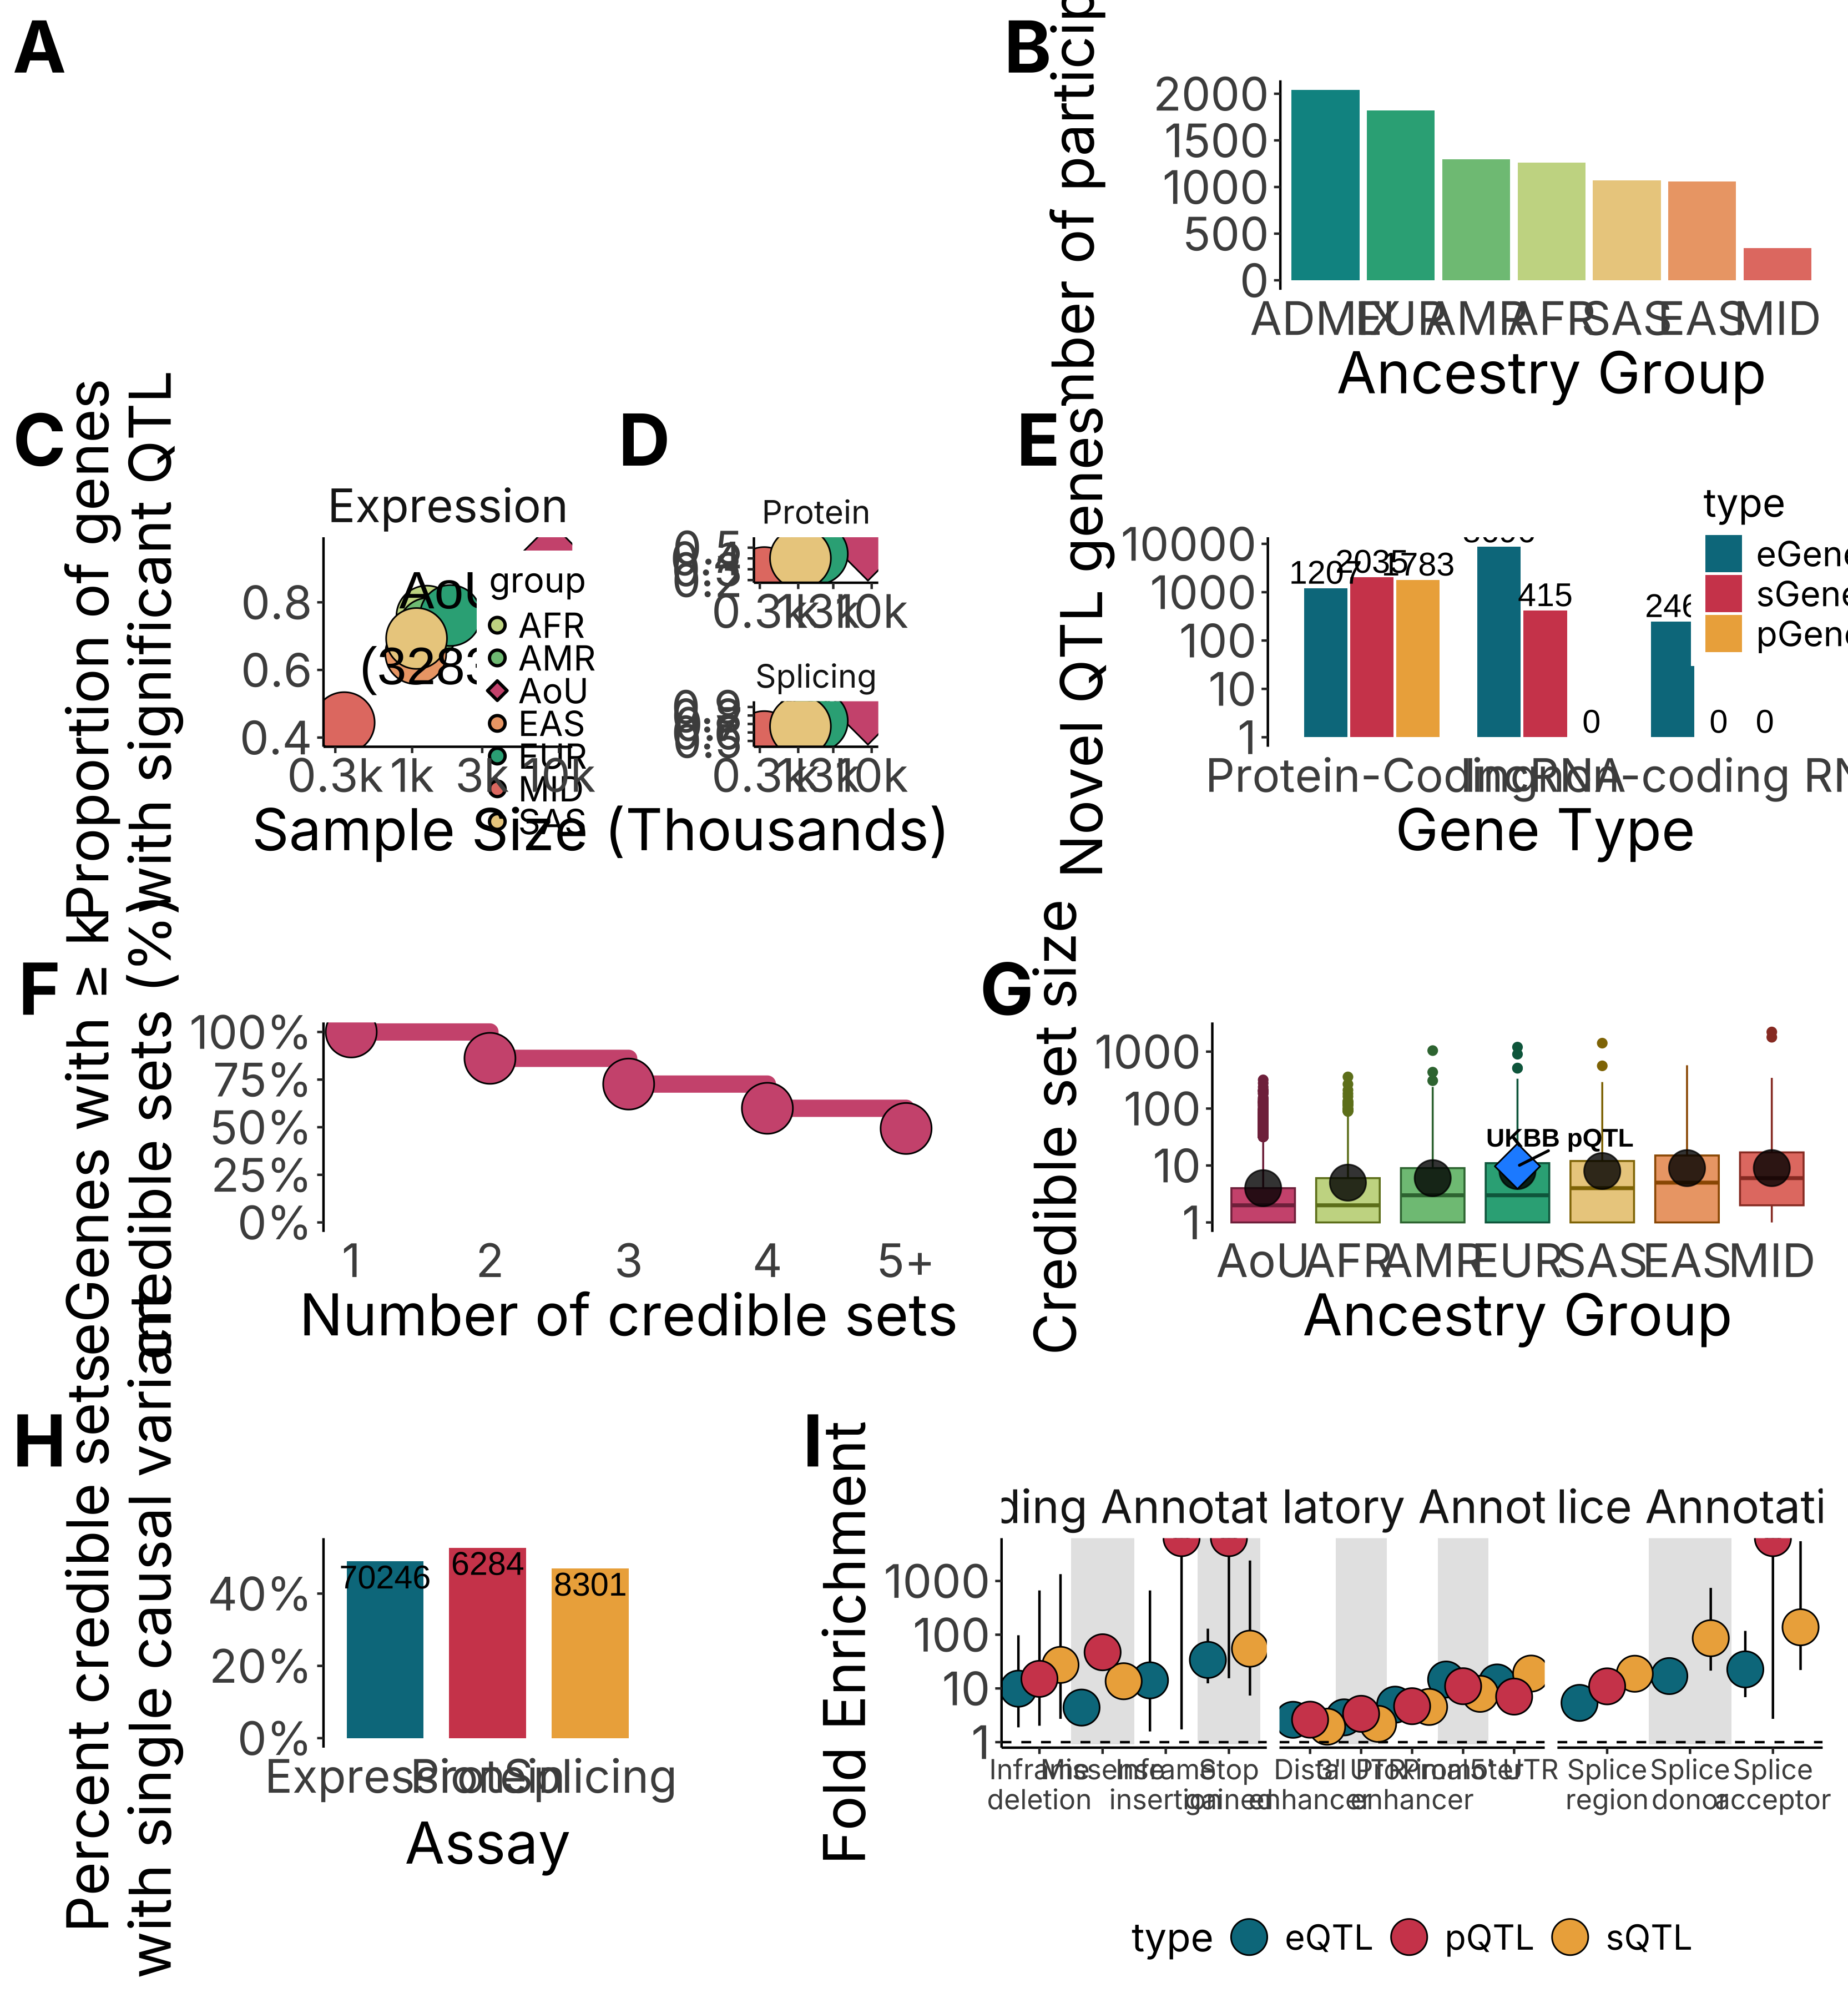

In [10]:
P <- setNames(lapply(LETTERS[1:8], function(x) readRDS(file.path(OBJ_DIR, paste0(x, ".rds")))),
              LETTERS[1:8])

top_row    <- P$A + (P$B + theme(plot.margin = margin(l = 60, unit = "pt")))
second_row <- (P$C + theme(plot.margin = margin(r = 60, b = 40, unit = "pt"))) |
              (P$D + theme(plot.margin = margin(b = 40, unit = "pt")))
third_row  <- P$E | (P$F + theme(plot.margin = margin(l = 20, b = 20, unit = "pt")))
bottom_row <- (P$G + theme(plot.margin = margin(r = 60, unit = "pt"))) + P$H +
              plot_layout(widths = c(1, 2.5))

Fig1 <- (top_row / second_row / third_row / bottom_row) +
  plot_annotation(tag_levels = "A") &
  theme(plot.tag = element_text(size = SZ_TAG, face = "bold", family = FONT))

ggsave(file.path(OUTDIR, "Figure1.pdf"), Fig1, width = 25, height = 27, dpi = DPI, limitsize = FALSE)
# Raster preview: full physical size at lower DPI (showtext DPI matched).
showtext_opts(dpi = 100)
ggsave(file.path(OUTDIR, "Figure1.png"), Fig1, width = 25, height = 27, dpi = 100, limitsize = FALSE)
showtext_opts(dpi = DPI)

message("Assembled: ", file.path(OUTDIR, "Figure1.pdf"), " and Figure1.png")

options(repr.plot.width = 11.1, repr.plot.height = 12.0)
Fig1


## **Supplemental (MetaSoft).** Cross-ancestry meta-analysis M-value summary. This step needs the external **MetaSoft** Java tool (`METASOFT_JAR`) and is skipped if its outputs are absent; it is not part of the main figure.


In [ ]:
METASOFT_JAR <- Sys.getenv("METASOFT_JAR", "Metasoft.jar")

# --- MetaSoft functions (folded from QTLAnalysisUtils, bug-fixed) -----------
FormatMetaSoft <- function(QTL_input) {
  QTL_input %>%
    filter(group != "COMB") %>%
    select(phenotype_id, slope, slope_se, group) %>%
    dplyr::rename("beta" = 2, "se" = 3) %>%
    pivot_wider(names_from = group, values_from = c(beta, se)) %>%
    na.omit() %>%
    dplyr::rename("SNP" = 1) %>%
    select(SNP, contains("AFR"), contains("SAS"), contains("EUR"),
           contains("AMR"), contains("EAS"), contains("MID"))
}

PlotMetaSoftMvaluesProps <- function(merged_metasoft) {
  merged_metasoft %>%
    select(RSID, V23, V24, V25, V26, V27, V28, type) %>%
    pivot_longer(!c(RSID, type)) %>%
    filter(value >= .9) %>%
    group_by(RSID, type) %>%
    summarize(mval_count = dplyr::n()) %>%
    group_by(type) %>%
    dplyr::count(mval_count) %>%
    mutate(prop = n / sum(n)) %>%
    ggplot(aes(x = mval_count, y = prop, fill = type)) +
    geom_col(position = "dodge") +
    xlab("Ancestry groups supporting effect  \n(Number of M vals >= .9 per gene)") +
    ylab("Proportion of genes") +
    paletteer::scale_fill_paletteer_d("ltc::minou")
}

# FIX: operate on the argument instead of a global `metasoft_all`.
PlotMetaSoftMvalueByPop <- function(merged_metasoft) {
  merged_metasoft %>%
    select(RSID, V23, V24, V25, V26, V27, V28, type) %>%
    na.omit() %>%
    dplyr::rename("AFR" = 2, "SAS" = 3, "EUR" = 4, "AMR" = 5, "EAS" = 6, "MID" = 7) %>%
    pivot_longer(!c(RSID, type)) %>%
    ggplot(aes(x = name, y = value, fill = name)) +
    geom_boxplot(show.legend = FALSE) +
    scale_fill_carto_d(palette = "Temps") +
    xlab("Population") +
    ylab("M-values") +
    facet_wrap(~type, nrow = 1)
}

# --- Read per-ancestry permutations via the manifest ------------------------
# The "perm" key covers all three assays; Assay is attached from the manifest.
assay_labels <- c(eQTL = "Expression", pQTL = "Protein", sQTL = "Splicing")
QTL_perm <- load_input("perm")

message("Preparing MetaSoft inputs ...")
for (a in names(assay_labels)) {
  QTL_perm %>%
    filter(Assay == assay_labels[[a]]) %>%
    FormatMetaSoft() %>%
    write_tsv(file.path(OUTDIR, paste0(a, "_wide_metasoft_input.tsv")), col_names = FALSE)
}

# --- Run MetaSoft (skipped if outputs already present) ----------------------
run_metasoft <- function(a) {
  out <- file.path(OUTDIR, paste0(a, ".metasoft.tsv"))
  if (file.exists(out)) { message("  using existing ", out); return(invisible()) }
  if (!file.exists(METASOFT_JAR))
    stop("MetaSoft jar not found at '", METASOFT_JAR, "'. Set METASOFT_JAR or pre-stage ",
         a, ".metasoft.tsv in OUTDIR.")
  system(paste("java -jar", shQuote(METASOFT_JAR), "-mvalue -input",
               file.path(OUTDIR, paste0(a, "_wide_metasoft_input.tsv")),
               "-output", out))
}
invisible(lapply(names(assay_labels), run_metasoft))

# --- Summarise and plot -----------------------------------------------------
metasoft_all <- purrr::map_dfr(names(assay_labels), function(a)
  fread(file.path(OUTDIR, paste0(a, ".metasoft.tsv"))) %>% mutate(type = a))

metasoft_plot_prop <- PlotMetaSoftMvaluesProps(metasoft_all)
metasoft_plot_pop  <- PlotMetaSoftMvalueByPop(metasoft_all)

# FIX: original composed the undefined `mvalue_per_pop` (the function's internal
# return-variable name); use the built plot object instead.
metasoft_summary <- (metasoft_plot_prop / metasoft_plot_pop) +
  plot_annotation(tag_levels = "A")

ggsave(file.path(OUTDIR, "xGeneMetasoftSummary.pdf"), metasoft_summary,
       width = 12, height = 7, dpi = DPI)
message("Wrote ", file.path(OUTDIR, "xGeneMetasoftSummary.pdf"))
